# Freight posted-rate prediction: analysis notebook

Spotter MLE take-home: predict `posted_rate` for the Nov–Dec 2025 validation loads and a December chart lane,
learning from Jan–Oct 2025 history.

**How to read this notebook.**
- Each section opens with a question and closes with a bold takeaway.
- The implementation lives in the `freight` package (`src/freight/`) and in `scripts/`. This notebook imports
  from the package and re-implements nothing.
- **Nothing is trained here.** Every number is printed by a cell. It is either read from a saved artifact
  under `artifacts/` (the traceable log is `artifacts/RESULTS.md`) or recomputed from `data/` with light
  pandas and the package helpers.
- To rerun: `make notebook` (the data files must be in `data/`; the per-fold predictions are not needed).

**Contents.**
1. Task and data
2. EDA
3. Data quality
4. Validation design
5. Phase 1: plain CatBoost
6. The fix: market level + CatBoost
7. Tuning
8. Final F3 results
9. Final predictions and sanity checks
10. The December chart
11. TabPack: a tabular deep-learning check
12. Limitations and next steps

In [1]:
# Setup: imports, house style and small display / plotting helpers (no modelling logic here).
import json
import re

import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from freight import config
from freight.backtest import EXPERIMENTS
from freight.data import clean, load_december, load_train, load_validation
from freight.features import city_coordinates, distance_band, haversine_miles
from freight.level import QE_MONTHS, MarketLevel, t_days
from freight.market import build_market_table, fill_market_index
from freight.models import LaneLevelBaseline
from freight.outliers import RpmReference
from freight.split import get_folds

ROOT, ART = config.ROOT, config.ARTIFACTS_DIR
plt.style.use(config.MPL_STYLE_PATH)  # reports/styles/report.mplstyle, resolved from the repo root
plt.rcParams["figure.dpi"] = 110  # smaller inline images; everything else is the house style
BLUE, GREEN, RED, AMBER, GRAY, INK = "#1565C0", "#2E7D32", "#C62828", "#F9A825", "#616161", "#1A2A3A"
LIGHT = "#EEEEEE"
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


def read_json(rel):
    return json.loads((ART / rel).read_text())


def read_csv(rel, **kw):
    return pd.read_csv(ART / rel, **kw)


def show(df, fmt=None, caption=None, index=False):
    """Render a DataFrame: floats 2 dp, ints with thousands separators, NaN as an en dash."""
    fmt = dict(fmt or {})
    for c in df.columns:
        if c not in fmt and pd.api.types.is_float_dtype(df[c]):
            fmt[c] = "{:,.2f}"
        elif c not in fmt and pd.api.types.is_integer_dtype(df[c]):
            fmt[c] = "{:,}"
    sty = df.style.format(fmt, na_rep="–")
    sty = sty if index else sty.hide(axis="index")
    display(sty.set_caption(caption) if caption else sty)


def takeaway(text):
    display(Markdown(f"**Takeaway: {text}**"))


def pct(x, digits=2):
    return f"{100 * x:+.{digits}f}%"


def pm(mean, sd, n, digits=1):
    return f"{mean:.{digits}f} ± {sd:.{digits}f}" if n > 1 else f"{mean:.{digits}f}"


def month_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))


def shade_validation(ax, text="Nov–Dec: inputs only, no labels"):
    ax.axvspan(VAL_START, VAL_END + pd.Timedelta(1, unit="D"), color=LIGHT, lw=0, zorder=0)
    if text:
        ax.text(VAL_START + pd.Timedelta(2, unit="D"), 0.97, text, transform=ax.get_xaxis_transform(),
                va="top", fontsize=8, color=GRAY)


def md_tables(text):
    """Pipe tables of a markdown text -> list of DataFrames (numeric columns converted)."""
    tables, block = [], []
    for line in text.splitlines() + [""]:
        if line.startswith("|"):
            block.append([c.strip() for c in line.strip().strip("|").split("|")])
        elif block:
            df = pd.DataFrame(block[2:], columns=block[0])
            for c in df.columns:
                num = pd.to_numeric(df[c], errors="coerce")
                df[c] = num if num.notna().all() else df[c]
            tables.append(df)
            block = []
    return tables


def md_section(path, number):
    """Text of section '## <number>. ...' of a markdown file."""
    parts = re.split(r"\n## ", path.read_text())
    return next(p for p in parts if p.startswith(f"{number}."))


def month_bias(name):
    """Median bias (pred / actual - 1, clean rows) by fold and test month from a backtest JSON; mean over runs."""
    rep = json.loads((config.BACKTEST_DIR / f"{name}.json").read_text())
    rows = [{"fold": res.get("fold", key), "month": m["month"], "bias": m["median_bias"]}
            for key, res in rep["folds"].items() for m in res["slices"]["month"]]
    return pd.DataFrame(rows).groupby(["fold", "month"], as_index=False)["bias"].mean()

## 1. Task and data at a glance

**Question.** What do we learn from, what must we predict, and what is new at prediction time?

The files on disk use **hyphens** (`train-test.csv`, `december-chart-inputs.csv`, …), although the brief spells
them with underscores. `freight.config` points at the names on disk.

In [2]:
train_raw, val_raw, dec_raw = load_train(), load_validation(), load_december()
VAL_START, VAL_END = val_raw["date"].min(), val_raw["date"].max()
print("CSV files in data/:", ", ".join(sorted(p.name for p in config.DATA_DIR.glob("*.csv"))))

overview = pd.DataFrame({
    "file": [config.TRAIN_PATH.name, config.VALIDATION_PATH.name, config.DECEMBER_PATH.name],
    "rows": [len(train_raw), len(val_raw), len(dec_raw)],
    "columns": [train_raw.shape[1], val_raw.shape[1], dec_raw.shape[1]],
    "first date": [f["date"].min().date() for f in (train_raw, val_raw, dec_raw)],
    "last date": [f["date"].max().date() for f in (train_raw, val_raw, dec_raw)],
    "target": ["posted_rate (labelled)", "to predict", "to predict (chart)"],
})
show(overview)

columns = pd.DataFrame({
    "column": train_raw.columns,
    "dtype": train_raw.dtypes.astype(str).to_numpy(),
    "missing in train": train_raw.isna().sum().to_numpy(),
    "in validation": [c in val_raw.columns for c in train_raw.columns],
    "in December chart": [c in dec_raw.columns for c in train_raw.columns],
})
show(columns)

CSV files in data/: december-chart-inputs.csv, train-test.csv, validation-predictions-template.csv, validation.csv


file,rows,columns,first date,last date,target
train-test.csv,"48,000",14,2025-01-01,2025-10-31,posted_rate (labelled)
validation.csv,"12,000",13,2025-11-01,2025-12-31,to predict
december-chart-inputs.csv,31,7,2025-12-01,2025-12-31,to predict (chart)


column,dtype,missing in train,in validation,in December chart
load_id,object,0,True,False
pickup,object,0,True,True
delivery,object,0,True,True
pickup_lat,float64,0,True,False
pickup_lon,float64,0,True,False
delivery_lat,float64,0,True,False
delivery_lon,float64,0,True,False
distance,float64,0,True,True
equipment,object,0,True,True
weight,float64,300,True,True


In [3]:
seen = set(train_raw["pickup"]) | set(train_raw["delivery"])
val_cities = set(val_raw["pickup"]) | set(val_raw["delivery"])
unseen = sorted(val_cities - seen)
cold_rows = val_raw["pickup"].isin(unseen) | val_raw["delivery"].isin(unseen)
lanes_seen = set(zip(train_raw["pickup"], train_raw["delivery"]))
lane_seen_share = pd.Series(list(zip(val_raw["pickup"], val_raw["delivery"]))).isin(lanes_seen).mean()
print(f"cities: {len(seen)} in training, {len(val_cities)} in validation")
print(f"validation-only cities ({len(unseen)}): {', '.join(unseen)}")
print(f"validation rows touching one: {cold_rows.sum():,} of {len(val_raw):,} ({cold_rows.mean():.1%}); "
      f"rows on a lane seen in training: {lane_seen_share:.1%}")

chart = dec_raw.drop(columns=["date", "predicted_rate"]).drop_duplicates()
assert len(chart) == 1
c = chart.iloc[0]
print(f"December chart: {c.pickup} → {c.delivery}, {c.equipment}, {c.distance} mi, {c.weight:,} lb, "
      f"{len(dec_raw)} dates; no market_index / quote_signal columns")
takeaway(f"an out-of-time task: learn from {len(train_raw):,} labelled loads ({train_raw.date.min():%b %d}–"
         f"{train_raw.date.max():%b %d}) and predict {len(val_raw):,} loads {VAL_START:%b %d}–{VAL_END:%b %d} "
         f"plus a {len(dec_raw)}-day chart; {len(unseen)} unseen cities touch {cold_rows.mean():.1%} of validation rows.")

cities: 64 in training, 72 in validation
validation-only cities (8): Allentown, Charlotte, Chicago, Jackson, Knoxville, Laredo, Norfolk, San Diego
validation rows touching one: 1,447 of 12,000 (12.1%); rows on a lane seen in training: 87.8%
December chart: Lexington → Fort Wayne, Dry Van, 360 mi, 32,000 lb, 31 dates; no market_index / quote_signal columns


**Takeaway: an out-of-time task: learn from 48,000 labelled loads (Jan 01–Oct 31) and predict 12,000 loads Nov 01–Dec 31 plus a 31-day chart; 8 unseen cities touch 12.1% of validation rows.**

## 2. EDA: key findings

**Question.** What drives the rate per mile, and what moves the overall price level from day to day?

Everything below uses **clean** rows: corrupted targets (Section 3) are removed with `freight.outliers.RpmReference`
(hierarchical lane × equipment median rpm) fitted on all Jan–Oct rows, exactly as in the final fit. The daily
market table (`freight.market.build_market_table`) pools the *input* columns of train and validation, and never the
labels. The **daily price index** is the mean over a day's clean loads of log(rpm / lane × equipment reference).
It is the quantity the market level L models later.

In [4]:
train = clean(train_raw)                           # sign-repaired weights + flags; no rows dropped
market = build_market_table(train, val_raw)        # daily market table, Jan 1 – Dec 31, inputs only
reference = RpmReference().fit(train)              # two-stage hierarchical median rpm (all Jan–Oct)
log_ratio = reference.log_ratio(train)
corrupted = log_ratio.abs() > config.OUTLIER_LOG_RATIO_THRESHOLD
clean_rows = train.loc[~corrupted].assign(rpm=lambda d: d["posted_rate"] / d["distance"],
                                          log_ratio=log_ratio[~corrupted])
level = MarketLevel(market).fit(clean_rows, clean_rows["log_ratio"])   # L on [1, mi_day_mean, t, qe_ramp]
idx = level.daily_["value"]                                            # daily price index
card = read_json("final/model_card.json")
saved = pd.Series(card["level"]["coefficients"])
print(f"{len(clean_rows):,} clean rows of {len(train):,}; L re-derived here equals model_card.json: "
      f"{np.allclose(level.coef_[saved.index], saved, rtol=1e-9)}")

47,323 clean rows of 48,000; L re-derived here equals model_card.json: True


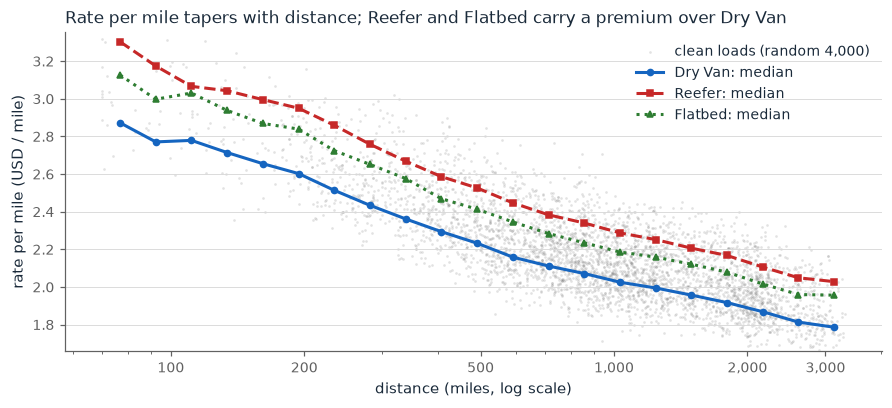

median rpm: $2.87 (0-150 mi) → $1.87 (2500+ mi); premium vs Dry Van (median over bands): Reefer +12.9%, Flatbed +8.4%


In [5]:
# Figure 1: rate per mile vs distance by equipment (binned medians over a light sample of loads).
edges = np.geomspace(clean_rows["distance"].min(), clean_rows["distance"].max() * 1.001, 22)
centers = np.sqrt(edges[:-1] * edges[1:])
bins = pd.cut(clean_rows["distance"], edges, right=False)
eq_style = {"Dry Van": (BLUE, "-", "o"), "Reefer": (RED, "--", "s"), "Flatbed": (GREEN, ":", "^")}

fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
sample = clean_rows.sample(4000, random_state=0)
ax.scatter(sample["distance"], sample["rpm"], s=3, color=GRAY, alpha=0.18, lw=0, label="clean loads (random 4,000)")
for eq, (col, ls, mk) in eq_style.items():
    med = clean_rows[clean_rows["equipment"] == eq].groupby(bins[clean_rows["equipment"] == eq], observed=False)["rpm"].median()
    ax.plot(centers, med.to_numpy(), color=col, ls=ls, marker=mk, ms=4, lw=2, label=f"{eq}: median")
ax.set_xscale("log")
ax.set_xticks([100, 200, 500, 1000, 2000, 3000], labels=["100", "200", "500", "1,000", "2,000", "3,000"])
lo_y, hi_y = clean_rows["rpm"].quantile([0.002, 0.998])
ax.set_ylim(lo_y, max(hi_y, clean_rows.groupby([bins, "equipment"], observed=True)["rpm"].median().max() + 0.05))
ax.set_xlabel("distance (miles, log scale)")
ax.set_ylabel("rate per mile (USD / mile)")
ax.set_title("Rate per mile tapers with distance; Reefer and Flatbed carry a premium over Dry Van", loc="left")
ax.legend(loc="upper right")
plt.show()

band = distance_band(clean_rows["distance"])
by_band = clean_rows.groupby([band, "equipment"])["rpm"].median().unstack()
premium = by_band.div(by_band["Dry Van"], axis=0).median()
band_med = clean_rows.groupby(band)["rpm"].median()
order = sorted(band_med.index, key=lambda s: float(s.split("-")[0].rstrip("+")))
print(f"median rpm: ${band_med[order[0]]:.2f} ({order[0]} mi) → ${band_med[order[-1]]:.2f} ({order[-1]} mi); "
      f"premium vs Dry Van (median over bands): Reefer {pct(premium['Reefer'] - 1, 1)}, Flatbed {pct(premium['Flatbed'] - 1, 1)}")

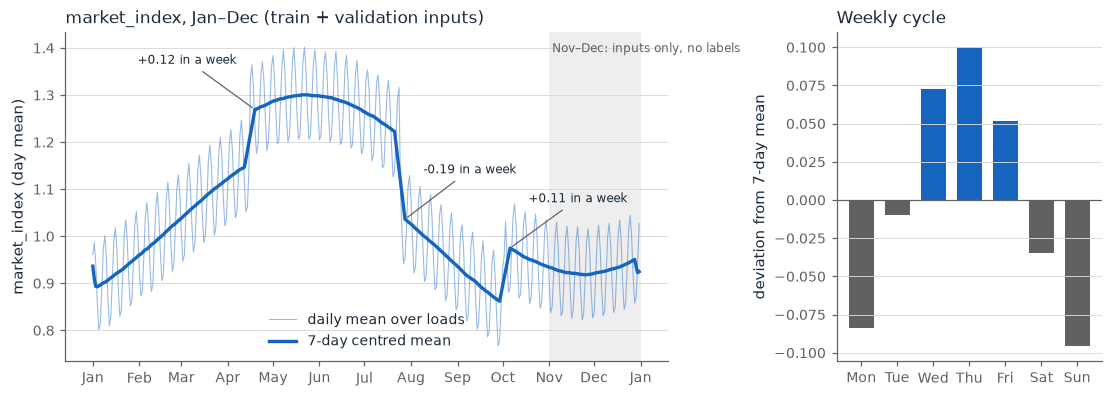

within-day sd of market_index 0.025 vs sd of daily means 0.165 → a market-wide daily signal, not a per-load one
weekly cycle: peak Thu +0.100, trough Sun -0.096
largest weekly shifts: Apr 19 +0.122; Jul 28 -0.187; Oct 06 +0.113


In [6]:
# Figure 2: the daily market_index is a market-wide signal with a weekly cycle and a few regime shifts.
mi = market["mi_day_mean"]
mi7 = mi.rolling(7, center=True, min_periods=4).mean()      # removes the weekly cycle
weekday = (mi - mi7).groupby(mi.index.dayofweek).mean()
rows_mi = pd.concat([train_raw[["date", "market_index"]], val_raw[["date", "market_index"]]])
within_day_sd = rows_mi.groupby("date")["market_index"].std().mean()
across_day_sd = mi.std()

step = mi7.diff(7).dropna()                                  # change of the weekly mean over 7 days
jumps = []
for day in step.abs().sort_values(ascending=False).index:    # three largest, at least a month apart
    if all(abs((day - j).days) > 30 for j in jumps):
        jumps.append(day)
    if len(jumps) == 3:
        break

fig, (ax, axw) = plt.subplots(1, 2, figsize=(10, 3.5), width_ratios=[2.5, 1.1], layout="constrained")
ax.plot(mi.index, mi, color=BLUE, lw=0.7, alpha=0.45, label="daily mean over loads")
ax.plot(mi7.index, mi7, color=BLUE, lw=2.2, label="7-day centred mean")
for j in jumps:
    ax.annotate(f"{step[j]:+.2f} in a week", xy=(j, mi7[j]), xytext=(-12, 30) if j.month < 7 else (12, 30),
                textcoords="offset points", ha="right" if j.month < 7 else "left", fontsize=8, color=INK,
                arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.8))
shade_validation(ax)
month_axis(ax)
ax.set_ylabel("market_index (day mean)")
ax.set_title("market_index, Jan–Dec (train + validation inputs)", loc="left")
ax.legend(loc="lower center")
labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
axw.bar(labels, weekday.to_numpy(), color=[BLUE if v > 0 else GRAY for v in weekday], width=0.7)
axw.axhline(0, color=GRAY, lw=0.8)
axw.set_ylabel("deviation from 7-day mean")
axw.set_title("Weekly cycle", loc="left")
plt.show()

print(f"within-day sd of market_index {within_day_sd:.3f} vs sd of daily means {across_day_sd:.3f} "
      f"→ a market-wide daily signal, not a per-load one")
print(f"weekly cycle: peak {labels[weekday.idxmax()]} {weekday.max():+.3f}, trough {labels[weekday.idxmin()]} {weekday.min():+.3f}")
print("largest weekly shifts:", "; ".join(f"{j:%b %d} {step[j]:+.3f}" for j in sorted(jumps)))

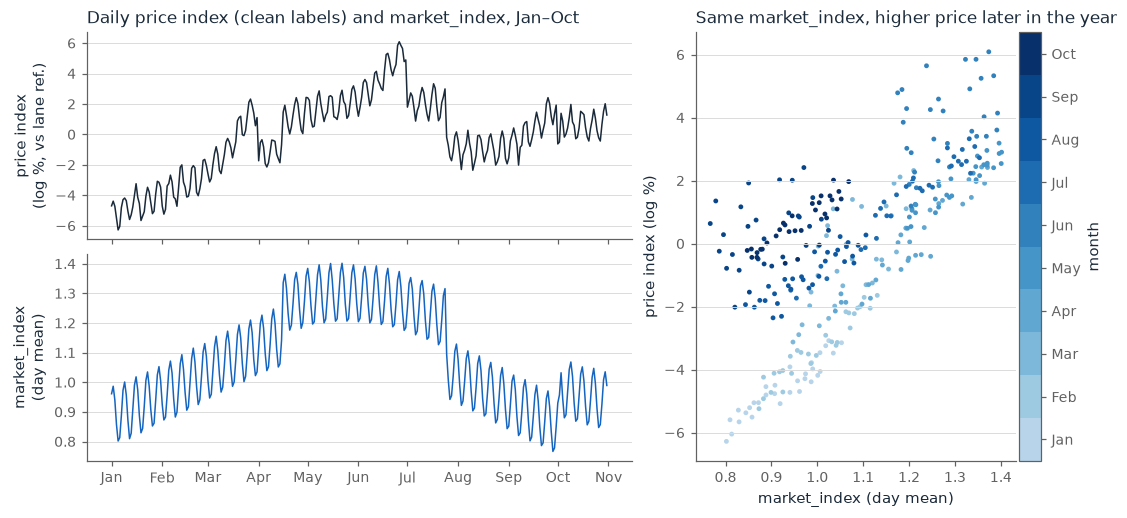

daily index ~,weighted R²,trend (% per 30 days)
mi_day_mean,0.499,–
mi_day_mean + t,0.854,0.53
mi_day_mean + t + qe_ramp,0.959,0.50


corr(daily index, market_index) = 0.70


In [7]:
# Figure 3: the daily price index follows market_index, but drifts upward at the same market_index.
fig = plt.figure(figsize=(10, 4.6), layout="constrained")
gs = fig.add_gridspec(2, 2, width_ratios=[1.7, 1])
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)
ax3 = fig.add_subplot(gs[:, 1])
ax1.plot(idx.index, 100 * idx, color=INK, lw=1.0)
ax1.set_ylabel("price index\n(log %, vs lane ref.)")
ax1.set_title("Daily price index (clean labels) and market_index, Jan–Oct", loc="left")
ax1.tick_params(labelbottom=False)
mi_train = mi.loc[idx.index]
ax2.plot(mi_train.index, mi_train, color=BLUE, lw=1.0)
ax2.set_ylabel("market_index\n(day mean)")
month_axis(ax2)
cmap = mcolors.ListedColormap(plt.cm.Blues(np.linspace(0.3, 1.0, 10)))
sc = ax3.scatter(mi_train, 100 * idx, c=idx.index.month, cmap=cmap, vmin=0.5, vmax=10.5, s=10, lw=0)
cb = fig.colorbar(sc, ax=ax3, ticks=range(1, 11), pad=0.01)
cb.ax.set_yticklabels(MONTHS[:10])
cb.set_label("month")
ax3.set_xlabel("market_index (day mean)")
ax3.set_ylabel("price index (log %)")
ax3.set_title("Same market_index, higher price later in the year", loc="left")
plt.show()

fits = {name: MarketLevel(market, terms).fit(clean_rows, clean_rows["log_ratio"]) for name, terms in {
    "mi_day_mean": ("mi_day_mean",),
    "mi_day_mean + t": ("mi_day_mean", "t"),
    "mi_day_mean + t + qe_ramp": ("mi_day_mean", "t", "qe_ramp")}.items()}
show(pd.DataFrame({"daily index ~": list(fits), "weighted R²": [f.r2_ for f in fits.values()],
                   "trend (% per 30 days)": [100 * 30 * f.coef_.get("t", np.nan) for f in fits.values()]}),
     fmt={"weighted R²": "{:.3f}", "trend (% per 30 days)": "{:.2f}"})
print(f"corr(daily index, market_index) = {np.corrcoef(idx, mi_train)[0, 1]:.2f}")

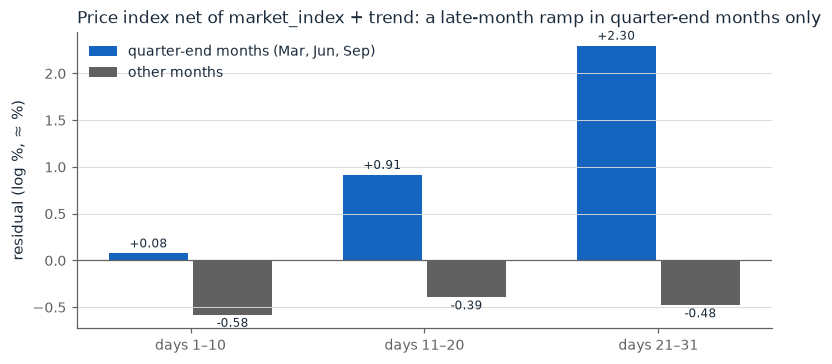

days 21–31 minus days 1–10: quarter-end months +2.22%, other months +0.10% → modelled as qe_ramp (0 until day 15, linear to 1 on the last day of Mar/Jun/Sep/Dec)


In [8]:
# Figure 4: the quarter-end ramp -- residual of the daily index after market_index + trend, by part of month.
no_ramp = fits["mi_day_mean + t"]
resid = no_ramp.daily_["value"] - no_ramp.daily_["fitted"]
part = pd.cut(resid.index.day, [0, 10, 20, 31], labels=["days 1–10", "days 11–20", "days 21–31"])
is_qe = np.isin(resid.index.month, list(QE_MONTHS))
ramp = (100 * resid).groupby([np.where(is_qe, "quarter-end months (Mar, Jun, Sep)", "other months"), part],
                             observed=True).mean().unstack(0)

fig, ax = plt.subplots(figsize=(7, 3.2), layout="constrained")
x = np.arange(len(ramp))
for k, (col, colr) in enumerate([("quarter-end months (Mar, Jun, Sep)", BLUE), ("other months", GRAY)]):
    bars = ax.bar(x + (k - 0.5) * 0.36, ramp[col], width=0.34, color=colr, label=col)
    ax.bar_label(bars, fmt="%+.2f", fontsize=8, padding=2)
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_xticks(x, ramp.index)
ax.set_ylabel("residual (log %, ≈ %)")
ax.set_title("Price index net of market_index + trend: a late-month ramp in quarter-end months only", loc="left")
ax.legend(loc="upper left")
plt.show()
QE, OTHER = "quarter-end months (Mar, Jun, Sep)", "other months"
lift_qe = ramp[QE].iloc[-1] - ramp[QE].iloc[0]
lift_other = ramp[OTHER].iloc[-1] - ramp[OTHER].iloc[0]
print(f"days 21–31 minus days 1–10: quarter-end months {lift_qe:+.2f}%, other months {lift_other:+.2f}% "
      f"→ modelled as qe_ramp (0 until day 15, linear to 1 on the last day of Mar/Jun/Sep/Dec)")

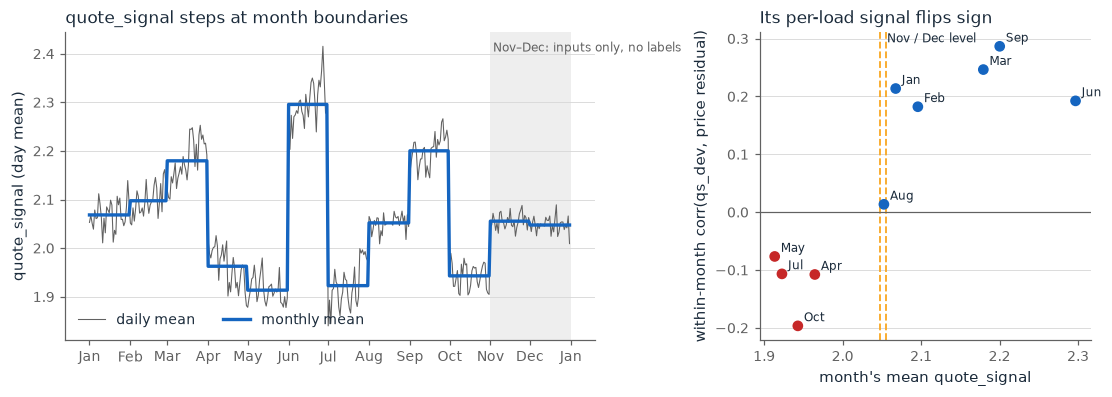

sd of monthly means 0.119 vs within-month daily sd 0.032 → a hidden month identifier
corr +0.18..+0.29 in months with level ≥ 2.07; -0.08..-0.20 with level ≤ 1.96; Aug ≈ 0 (+0.01) at 2.05; Nov / Dec levels 2.06, 2.05 sit in that undecided zone


**Takeaway: rate per mile is set by distance, equipment and a daily price level. That level follows market_index (a daily market-wide signal with a Thu peak and a Sun trough) plus an upward trend and a quarter-end ramp: R² 0.50 → 0.85 → 0.96. quote_signal is a month identifier with an unstable sign, not a price signal.**

In [9]:
# Figure 5: quote_signal is a trap -- a monthly level that steps at month boundaries, and a per-load part whose
# relation to price flips sign with that level.
qs = market["qs_day_mean"]
qs_month = qs.groupby(qs.index.to_period("M")).transform("mean")
sd_monthly = qs.groupby(qs.index.to_period("M")).mean().std()
sd_within = (qs - qs_month).std()

qd = clean_rows.assign(
    qs_dev=clean_rows["quote_signal"] - qs.reindex(clean_rows["date"]).to_numpy(),         # per-load part
    resid=clean_rows["log_ratio"] - clean_rows.groupby("date")["log_ratio"].transform("mean"),  # net of the day level
    month=clean_rows["date"].dt.to_period("M"))
flip = qd.groupby("month")[["quote_signal", "qs_dev", "resid"]].apply(
    lambda g: pd.Series({"qs level": g["quote_signal"].mean(), "corr": g["qs_dev"].corr(g["resid"])}))
qs_future = qs.loc[VAL_START:].groupby(qs.loc[VAL_START:].index.to_period("M")).mean()

fig, (ax, axr) = plt.subplots(1, 2, figsize=(10, 3.5), width_ratios=[1.6, 1], layout="constrained")
ax.plot(qs.index, qs, color=GRAY, lw=0.7, label="daily mean")
ax.plot(qs_month.index, qs_month, color=BLUE, lw=2.2, label="monthly mean")
shade_validation(ax)
month_axis(ax)
ax.set_ylabel("quote_signal (day mean)")
ax.set_title("quote_signal steps at month boundaries", loc="left")
ax.legend(loc="lower left", ncols=2)
colors = [BLUE if v > 0 else RED for v in flip["corr"]]
axr.scatter(flip["qs level"], flip["corr"], c=colors, s=36, zorder=3)
for m, r in flip.iterrows():
    axr.annotate(MONTHS[m.month - 1], (r["qs level"], r["corr"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
for m, v in qs_future.items():
    axr.axvline(v, color=AMBER, lw=1.2, ls="--")
axr.text(qs_future.mean(), axr.get_ylim()[1], " Nov / Dec level", color=INK, fontsize=8, va="top")
axr.axhline(0, color=GRAY, lw=0.8)
axr.set_xlabel("month's mean quote_signal")
axr.set_ylabel("within-month corr(qs_dev, price residual)")
axr.set_title("Its per-load signal flips sign", loc="left")
plt.show()

hi, lo, mid = flip[flip["corr"] > 0.05], flip[flip["corr"] < -0.05], flip[flip["corr"].abs() <= 0.05]
print(f"sd of monthly means {sd_monthly:.3f} vs within-month daily sd {sd_within:.3f} → a hidden month identifier")
print(f"corr {hi['corr'].min():+.2f}..{hi['corr'].max():+.2f} in months with level ≥ {hi['qs level'].min():.2f}; "
      f"{lo['corr'].max():+.2f}..{lo['corr'].min():+.2f} with level ≤ {lo['qs level'].max():.2f}; "
      + ", ".join(f"{MONTHS[m.month - 1]} ≈ 0 ({r['corr']:+.2f}) at {r['qs level']:.2f}" for m, r in mid.iterrows())
      + f"; Nov / Dec levels {', '.join(f'{v:.2f}' for v in qs_future)} sit in that undecided zone")
takeaway(f"rate per mile is set by distance, equipment and a daily price level. That level follows market_index "
         f"(a daily market-wide signal with a Thu peak and a Sun trough) plus an upward trend and a quarter-end ramp: "
         f"R² {fits['mi_day_mean'].r2_:.2f} → {fits['mi_day_mean + t'].r2_:.2f} → {fits['mi_day_mean + t + qe_ramp'].r2_:.2f}. "
         f"quote_signal is a month identifier with an unstable sign, not a price signal.")

## 3. Data quality

**Question.** Which rows or values are wrong, and how is each problem handled without dropping validation rows?

- **Targets.** Corrupted targets are removed from *training* only. Metrics are reported on "clean" test rows,
  and on "all" test rows for reference.
- **Inputs.** Inputs are repaired in `freight.data.clean`: absolute weight, flags for weights sitting on the cap
  or floor, and weight missingness kept as NaN plus a flag.
- **Missing market_index.** Filled with the day's market-wide mean (`freight.market.fill_market_index`).

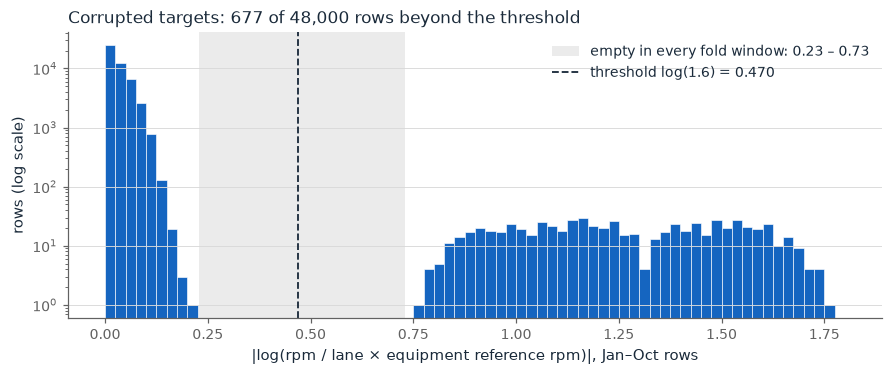

flagged: 677 = 340 too high (×2.2–5.5) + 337 too low (×0.17–0.47)
same count in outlier_threshold.json (677) and model_card.json (677); flagged share per fold test window: F1 1.3%, F2 1.4%, F3 1.5%
flag rate by month 1.3%–1.6%; by equipment Dry Van 1.4%, Flatbed 1.5%, Reefer 1.5%


In [10]:
# Figure 6: |log(rpm / lane reference)| is bimodal; log(1.6) sits in an empty gap.
thr = config.OUTLIER_LOG_RATIO_THRESHOLD
ot = read_json("backtest/outlier_threshold.json")
windows = {k: v for k, v in ot.items() if isinstance(v, dict)}
genuine_max = max(v["genuine_max"] for v in windows.values())       # over every fold's train and test window
corrupted_min = min(v["corrupted_min"] for v in windows.values())
a = log_ratio.abs()
n_high, n_low = int((log_ratio > thr).sum()), int((log_ratio < -thr).sum())

fig, ax = plt.subplots(figsize=(8, 3.3), layout="constrained")
ax.hist(a, bins=np.arange(0, a.max() + 0.05, 0.025), color=BLUE, edgecolor="white", linewidth=0.4)
ax.set_yscale("log")
ax.axvspan(genuine_max, corrupted_min, color=GRAY, alpha=0.12, lw=0,
           label=f"empty in every fold window: {genuine_max:.2f} – {corrupted_min:.2f}")
ax.axvline(thr, color=INK, lw=1.2, ls="--", label=f"threshold log(1.6) = {thr:.3f}")
ax.set_xlabel("|log(rpm / lane × equipment reference rpm)|, Jan–Oct rows")
ax.set_ylabel("rows (log scale)")
ax.set_title(f"Corrupted targets: {n_high + n_low} of {len(a):,} rows beyond the threshold", loc="left")
ax.legend(loc="upper right")
plt.show()

hi_mult = np.exp(log_ratio[log_ratio > thr]).agg(["min", "max"])
lo_mult = np.exp(log_ratio[log_ratio < -thr]).agg(["min", "max"])
print(f"flagged: {n_high + n_low} = {n_high} too high (×{hi_mult['min']:.1f}–{hi_mult['max']:.1f}) + "
      f"{n_low} too low (×{lo_mult['min']:.2f}–{lo_mult['max']:.2f})")
print(f"same count in outlier_threshold.json ({ot['all_train']['flagged']}) and model_card.json "
      f"({card['training']['n_excluded_corrupted']}); flagged share per fold test window: "
      + ", ".join(f"{f.name} {ot[f'{f.name}_test']['flagged'] / ot[f'{f.name}_test']['n']:.1%}" for f in get_folds()))
by_month = corrupted.groupby(train["date"].dt.month).mean()
print(f"flag rate by month {by_month.min():.1%}–{by_month.max():.1%}; by equipment "
      + ", ".join(f"{k} {v:.1%}" for k, v in corrupted.groupby(train['equipment']).mean().items()))

In [11]:
# Weight and market_index anomalies (counts from the raw files; handling in freight.data.clean / freight.market).
def anomalies(raw):
    w = raw["weight"]
    return {"weight sign-flipped (negative)": (w < 0).sum(), "weight at cap 47,500 lb": (w.abs() == config.WEIGHT_CAP).sum(),
            "weight at floor 5,000 lb": (w.abs() == config.WEIGHT_FLOOR).sum(), "weight missing (NaN)": w.isna().sum(),
            "market_index missing (NaN)": raw["market_index"].isna().sum()}

flags = {"weight sign-flipped (negative)": "weight_was_negative", "weight at cap 47,500 lb": "weight_at_cap",
         "weight at floor 5,000 lb": "weight_at_floor", "weight missing (NaN)": "weight_missing",
         "market_index missing (NaN)": "mi_missing"}
handling = {"weight sign-flipped (negative)": "abs() + flag", "weight at cap 47,500 lb": "keep + flag (censored)",
            "weight at floor 5,000 lb": "keep + flag (censored)", "weight missing (NaN)": "keep NaN (CatBoost) + flag",
            "market_index missing (NaN)": "day mean of market_index + flag"}
tab = pd.DataFrame({"train": anomalies(train_raw), "validation": anomalies(val_raw)}).rename_axis("issue").reset_index()
tab["median log-ratio of clean train rows (%)"] = [100 * clean_rows.loc[clean_rows[flags[i]] == 1, "log_ratio"].median()
                                                   for i in tab["issue"]]
tab["handling"] = tab["issue"].map(handling)
show(tab, fmt={"median log-ratio of clean train rows (%)": "{:+.2f}"})
print("max |weight| =", f"{train_raw['weight'].abs().max():,.0f}", "; min |weight| =", f"{train_raw['weight'].abs().min():,.0f}",
      "→ the cap and floor are sentinels, not real loads")

filled = fill_market_index(train, market)
print(f"market_index after the day-mean fill: {filled.isna().sum()} NaN left; the fill's typical error is the "
      f"within-day sd {within_day_sd:.3f}, vs a day-to-day sd of {across_day_sd:.3f}")

issue,train,validation,median log-ratio of clean train rows (%),handling
weight sign-flipped (negative),292,145,+0.00,abs() + flag
"weight at cap 47,500 lb","1,204",301,+2.49,keep + flag (censored)
"weight at floor 5,000 lb",32,7,-3.89,keep + flag (censored)
weight missing (NaN),300,165,+0.00,keep NaN (CatBoost) + flag
market_index missing (NaN),374,249,+0.00,day mean of market_index + flag


max |weight| = 47,500 ; min |weight| = 5,000 → the cap and floor are sentinels, not real loads
market_index after the day-mean fill: 0 NaN left; the fill's typical error is the within-day sd 0.025, vs a day-to-day sd of 0.165


In [12]:
# Coordinates are distorted (and clipped) but consistent: one coordinate pair per city, a stable road/crow-fly ratio.
coords = city_coordinates(train_raw, val_raw)          # raises if a city ever had two coordinate pairs
hav = haversine_miles(train_raw["pickup_lat"], train_raw["pickup_lon"], train_raw["delivery_lat"], train_raw["delivery_lon"])
circuity = pd.Series(train_raw["distance"].to_numpy() / np.clip(hav, 1, None))
q = circuity.quantile([0.05, 0.5, 0.95])
clipped = coords[(coords["lat"] == coords["lat"].min()) | (coords["lon"] == coords["lon"].max())]
print(f"{len(coords)} cities, each with exactly one coordinate pair; clipped at lat {coords['lat'].min()} / lon "
      f"{coords['lon'].max()}: {', '.join(clipped.index)}")
print(f"Los Angeles sits at lat {coords.loc['Los Angeles', 'lat']:.2f} (true ≈ 34.05): positions are distorted")
print(f"road distance / haversine: median {q[0.5]:.3f} (5–95%: {q[0.05]:.3f}–{q[0.95]:.3f}); "
      f"corr(distance, haversine) = {np.corrcoef(train_raw['distance'], hav)[0, 1]:.4f} → usable as internal geometry")
takeaway(f"{n_high + n_low} corrupted targets ({(n_high + n_low) / len(train):.1%}) sit beyond an empty gap and are "
         f"dropped from training. Weight sentinels and sign flips are repaired and flagged. Missing market_index gets "
         f"the day mean. Coordinates are distorted but consistent, so they can stand in for unseen city IDs.")

72 cities, each with exactly one coordinate pair; clipped at lat 25.5 / lon -69.5: Providence, Boston, Laredo
Los Angeles sits at lat 28.57 (true ≈ 34.05): positions are distorted
road distance / haversine: median 1.182 (5–95%: 1.143–1.273); corr(distance, haversine) = 0.9995 → usable as internal geometry


**Takeaway: 677 corrupted targets (1.4%) sit beyond an empty gap and are dropped from training. Weight sentinels and sign flips are repaired and flagged. Missing market_index gets the day mean. Coordinates are distorted but consistent, so they can stand in for unseen city IDs.**

## 4. Validation design

**Question.** How do we measure accuracy honestly for a forecast one to two months ahead?

- **Forward-time folds only.** Random K-fold would let the model interpolate inside weeks it has already seen,
  and it would hide exactly the failure seen in Section 5: extrapolating the price level into unseen months.
  Every fold trains on Jan 1 → cut-off and tests on the next **two** months, which mirrors Nov–Dec after Oct 31.
- **Protocol.** Every choice (feature set, level terms, hyper-parameters) is made on **F1 + F2**. F3 is scored
  once with the final choice. The final model is refit on all of Jan–Oct.
- **Cold-start slice.** The design holds out 8 random cities from the training window, which simulates the 8
  validation-only cities.
- **Reference.** The corrupted-target reference is refit per fold on training rows only.

fold,role,train,test,train rows,test rows,flagged train / test
F1,tuning / selection,Jan 01 – Apr 30,May 01 – Jun 30,"19,110","9,696",275 / 125
F2,tuning / selection,Jan 01 – Jun 30,Jul 01 – Aug 31,"28,806","9,671",400 / 133
F3,"holdout, scored once",Jan 01 – Aug 31,Sep 01 – Oct 31,"38,477","9,523",533 / 144
final,refit → deliverables,Jan 01 – Oct 31,Nov 01 – Dec 31 (predict),"48,000","12,000",677 / –


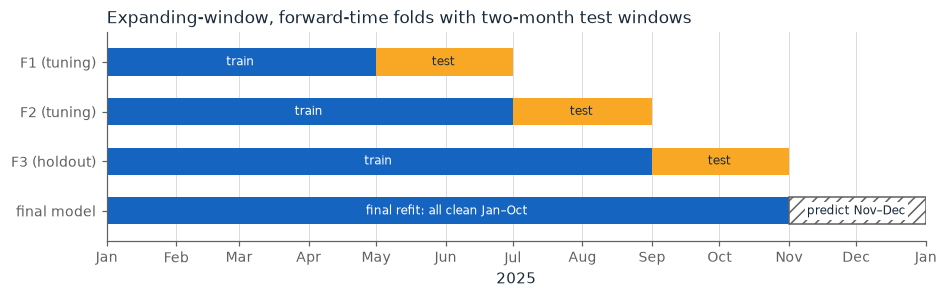

**Takeaway: three expanding forward-time folds with two-month tests; F1 + F2 decide everything, F3 is the untouched report, and a cold-start slice measures the unseen-city cost.**

In [13]:
fold_rows = []
for f in get_folds():
    fold_rows.append({
        "fold": f.name, "role": "tuning / selection" if f.name in config.TUNING_FOLDS else "holdout, scored once",
        "train": f"{f.train_start:%b %d} – {f.train_end:%b %d}", "test": f"{f.test_start:%b %d} – {f.test_end:%b %d}",
        "train rows": int(f.train_mask(train).sum()), "test rows": int(f.test_mask(train).sum()),
        "flagged train / test": f"{ot[f'{f.name}_train']['flagged']} / {ot[f'{f.name}_test']['flagged']}"})
fold_rows.append({"fold": "final", "role": "refit → deliverables",
                  "train": f"{train.date.min():%b %d} – {train.date.max():%b %d}", "test": f"{VAL_START:%b %d} – {VAL_END:%b %d} (predict)",
                  "train rows": len(train), "test rows": len(val_raw), "flagged train / test": f"{ot['all_train']['flagged']} / –"})
show(pd.DataFrame(fold_rows))

# Figure 7: timeline of the folds, the final refit and the prediction window.
fig, ax = plt.subplots(figsize=(8.5, 2.6), layout="constrained")
ax.set_axisbelow(True)
one = pd.Timedelta(1, unit="D")
ylabels = []
for y, f in enumerate(get_folds()):
    ax.barh(y, f.train_end + one - f.train_start, left=f.train_start, color=BLUE, height=0.55)
    ax.barh(y, f.test_end + one - f.test_start, left=f.test_start, color=AMBER, height=0.55)
    ax.text(f.train_start + (f.train_end - f.train_start) / 2, y, "train", color="white", ha="center", va="center", fontsize=8)
    ax.text(f.test_start + (f.test_end - f.test_start) / 2, y, "test", color=INK, ha="center", va="center", fontsize=8)
    ylabels.append(f"{f.name} ({'tuning' if f.name in config.TUNING_FOLDS else 'holdout'})")
y = len(ylabels)
ax.barh(y, train.date.max() + one - train.date.min(), left=train.date.min(), color=BLUE, height=0.55)
ax.barh(y, VAL_END + one - VAL_START, left=VAL_START, color="white", edgecolor=GRAY, hatch="///", height=0.55)
ax.text(train.date.min() + (train.date.max() - train.date.min()) / 2, y, "final refit: all clean Jan–Oct",
        color="white", ha="center", va="center", fontsize=8)
ax.text(VAL_START + (VAL_END - VAL_START) / 2, y, "predict Nov–Dec", color=INK, ha="center", va="center", fontsize=8,
        bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ylabels.append("final model")
ax.set_yticks(range(len(ylabels)), ylabels)
ax.set_ylim(len(ylabels) - 0.4, -0.6)
month_axis(ax)
ax.set_xlim(pd.Timestamp(config.DATE_ORIGIN), VAL_END + one)
ax.grid(axis="x", color="#D9D9D9", lw=0.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("2025")
ax.set_title("Expanding-window, forward-time folds with two-month test windows", loc="left")
plt.show()
takeaway("three expanding forward-time folds with two-month tests; F1 + F2 decide everything, F3 is the untouched "
         "report, and a cold-start slice measures the unseen-city cost.")

## 5. Phase 1: plain CatBoost and the second-month collapse

**Question.** How far does a standard CatBoost on all features get, and where does it fail?

Experiments E0–E5 (single seed, clean-row MAE in $):
- **E0** yardstick: lane × equipment median rpm × distance.
- **E1** CatBoost on log(rpm) without a time coordinate.
- **E2** the same with a log(rate) target.
- **E3** adds a `t_days` coordinate.
- **E4** keeps the corrupted rows in training.
- **E5** uses only the raw market columns.

In [14]:
summary = read_csv("backtest/summary.csv")
p1_names = ["yardstick", "cb_base", "cb_lograte", "cb_time", "cb_keep_outliers", "cb_raw_market"]
p1 = summary[summary["experiment"].isin(p1_names) & summary["fold"].isin(["F1", "F2", "F3"])]
p1 = p1.sort_values("run_at").groupby(["experiment", "fold"]).tail(1)        # latest single-seed run per fold
mae = p1.pivot(index="experiment", columns="fold", values="mae_clean").loc[p1_names]
mape = p1[p1["fold"] == "F3"].set_index("experiment")["mape_clean"]
bias3 = {n: month_bias(n).query("fold == 'F3'").set_index("month")["bias"] for n in p1_names}
tab = pd.DataFrame({
    "id": [EXPERIMENTS[n].exp_id for n in p1_names], "experiment": p1_names,
    "description": [EXPERIMENTS[n].description for n in p1_names],
    "F1": mae["F1"].to_numpy(), "F2": mae["F2"].to_numpy(), "F3": mae["F3"].to_numpy(),
    "F3 MAPE %": mape.loc[p1_names].to_numpy(),
    "F3 bias Sep %": [100 * bias3[n].iloc[0] for n in p1_names], "F3 bias Oct %": [100 * bias3[n].iloc[1] for n in p1_names]})
show(tab, fmt={c: "{:.1f}" for c in ["F1", "F2", "F3"]} | {c: "{:+.2f}" for c in ["F3 bias Sep %", "F3 bias Oct %"]},
     caption="MAE clean ($), single seed; source backtest/summary.csv and the per-experiment JSONs")
print("cb_time month bias comes from its 3-seed re-run (backtest/cb_time.json); its single-seed JSON was overwritten.")

id,experiment,description,F1,F2,F3,F3 MAPE %,F3 bias Sep %,F3 bias Oct %
E0,yardstick,"Lane-median rpm x distance, fit on clean training rows",148.8,83.8,76.2,3.21,-0.65,-1.05
E1,cb_base,"CatBoost, log_rpm, corrupted rows dropped, no time coordinate",80.9,69.0,88.5,4.52,-2.47,-6.49
E2,cb_lograte,E1 with a log_rate target,63.6,58.4,91.4,4.43,-2.76,-6.16
E3,cb_time,E1 + t_days time coordinate,87.6,66.8,53.8,2.17,-1.50,-2.70
E4,cb_keep_outliers,E1 but corrupted rows kept in training,151.8,61.5,110.0,4.66,-3.57,-5.16
E5,cb_raw_market,E1 without daily-market-table features (raw market_index + quote_signal only),55.7,64.6,72.8,3.18,-2.02,-4.20


cb_time month bias comes from its 3-seed re-run (backtest/cb_time.json); its single-seed JSON was overwritten.


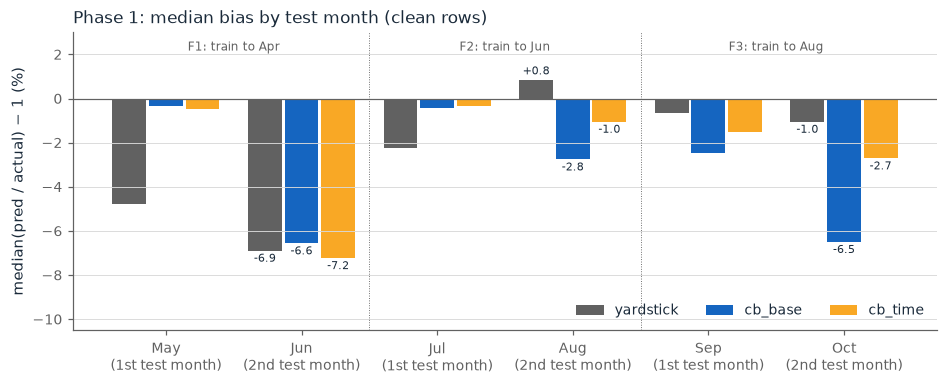

second-month bias: cb_base Jun -6.6%, Aug -2.8%, Oct -6.5%; cb_time Jun -7.2%, Aug -1.0%, Oct -2.7%


In [15]:
# Figure 8: median bias by test month -- fine in the first month, too low in the second.
series = {"yardstick": GRAY, "cb_base": BLUE, "cb_time": AMBER}
mb = {n: month_bias(n).set_index("month")["bias"] for n in series}
months = mb["cb_base"].index.tolist()
fig, ax = plt.subplots(figsize=(8.5, 3.4), layout="constrained")
x = np.arange(len(months))
for k, (name, col) in enumerate(series.items()):
    vals = 100 * mb[name].reindex(months).to_numpy()
    bars = ax.bar(x + (k - 1) * 0.27, vals, width=0.25, color=col, label=name)
    ax.bar_label(bars, labels=[f"{v:+.1f}" if i % 2 else "" for i, v in enumerate(vals)], fontsize=7, padding=2)
ax.axhline(0, color=GRAY, lw=0.8)
for b in (1.5, 3.5):
    ax.axvline(b, color=GRAY, lw=0.6, ls=":")
for i, f in enumerate(get_folds()):
    ax.text(2 * i + 0.5, 0.97, f"{f.name}: train to {f.train_end:%b}", transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=8, color=GRAY)
ax.set_xticks(x, [f"{MONTHS[int(m[-2:]) - 1]}\n({'1st' if i % 2 == 0 else '2nd'} test month)" for i, m in enumerate(months)])
ax.set_ylabel("median(pred / actual) − 1 (%)")
ax.set_title("Phase 1: median bias by test month (clean rows)", loc="left")
ax.set_ylim(min(-10.5, ax.get_ylim()[0]), 3)
ax.legend(loc="lower right", ncols=3)
plt.show()

m2 = {n: 100 * mb[n].iloc[1::2] for n in ("cb_base", "cb_time")}
print("second-month bias:", "; ".join(f"{n} " + ", ".join(f"{MONTHS[int(m[-2:]) - 1]} {v:+.1f}%" for m, v in s.items())
                                        for n, s in m2.items()))

In [16]:
# Diagnosis: the trees lean on level carriers / month proxies (E1 on F3, PredictionValuesChange importance).
imp = read_csv("backtest/e1_f3_importance.csv")
imp["level / month carrier"] = imp["feature"].isin(config.LEVEL_CB_EXCLUDED)
share = imp.loc[imp["level / month carrier"], "importance"].sum() / imp["importance"].sum()
show(imp.head(12).assign(importance=lambda d: d["importance"].round(2)), caption="cb_base, F3: top-12 features")
print(f"importance on level carriers / month proxies ({', '.join(sorted(config.LEVEL_CB_EXCLUDED))}): {share:.1%}")
m1 = {n: 100 * mb[n].iloc[0::2] for n in ("cb_base", "cb_time")}
takeaway(f"plain trees get the first test month roughly right (|bias| ≤ {max(s.abs().max() for s in m1.values()):.1f}%) but "
         f"under-predict the second, down to {min(s.min() for s in m2.values()):.1f}% "
         f"(cb_base: {', '.join(f'{v:+.1f}%' for v in m2['cb_base'])} on F1 / F2 / F3). A tree cannot extrapolate a rising "
         f"level, and month proxies such as quote_signal's monthly level, trailing means and days_to_quarter_end let it "
         f"reuse older, lower levels.")

feature,importance,level / month carrier
equipment,24.23,False
log_distance,20.88,False
distance,12.79,False
haversine_mi,10.77,False
quote_signal,6.09,True
weight,5.62,False
mi_ma28,4.36,True
market_index,3.03,True
mi_ma7,2.33,True
mi_day_mean,1.68,True


importance on level carriers / month proxies (days_to_month_end, days_to_quarter_end, market_index, mi_day_mean, mi_ma28, mi_ma7, quote_signal, t_days): 19.1%


**Takeaway: plain trees get the first test month roughly right (|bias| ≤ 2.5%) but under-predict the second, down to -7.2% (cb_base: -6.6%, -2.8%, -6.5% on F1 / F2 / F3). A tree cannot extrapolate a rising level, and month proxies such as quote_signal's monthly level, trailing means and days_to_quarter_end let it reuse older, lower levels.**

## 6. The fix: market level + CatBoost

**Question.** Can the daily price level be taken away from the trees and handed to a model that extrapolates?

$$\log(\text{rpm}_i) = L(d_i) + f(x_i), \qquad
L(d) = \beta_0 + \beta_{mi}\,\overline{mi}(d) + \beta_t\,t(d) + \beta_{qe}\,\mathit{ramp}_{qe}(d), \qquad
\text{rate}_i = \text{distance}_i\, e^{L + f}$$

- **L** (`freight.level.MarketLevel`) is a weighted OLS on the daily price index. It uses the day's
  market-wide market_index (known for Nov–Dec from validation inputs), a linear trend $t$ in days, and the
  quarter-end ramp.
- **f** is a CatBoost with L as its **baseline**. It only sees cross-sectional features: lanes, cities,
  coordinates, distance, weight, `mi_dev` (the load's deviation from the day's market_index), day of week and
  day of month. Every level carrier and month proxy is excluded (`config.LEVEL_CB_EXCLUDED`).

In [17]:
coefs = read_json("backtest/level_coefficients.json")
rows = []
for name, e in coefs["folds"].items():
    oos = e.get("oos_level_error_pred_minus_actual", {}).get("by_month", {})
    window = config.FOLD_DATES.get(name, (config.DATE_ORIGIN, str(train.date.max().date())))
    rows.append({"fit": name, "train window": f"{pd.Timestamp(window[0]):%b} – {pd.Timestamp(window[1]):%b}",
                 "β0": e["const"], "β_mi": e["mi_day_mean"], "β_t (% / 30 days)": 100 * 30 * e["t"],
                 "qe_ramp effect on last day (%)": 100 * np.expm1(e["qe_ramp"]), "R² (daily, weighted)": e["r2_daily_weighted"],
                 "L error, 1st test month (%)": 100 * list(oos.values())[0] if oos else np.nan,
                 "L error, 2nd test month (%)": 100 * list(oos.values())[1] if oos else np.nan})
show(pd.DataFrame(rows), fmt={"β0": "{:+.4f}", "β_mi": "{:.4f}", "β_t (% / 30 days)": "{:.2f}",
                              "qe_ramp effect on last day (%)": "{:+.2f}", "R² (daily, weighted)": "{:.3f}",
                              "L error, 1st test month (%)": "{:+.2f}", "L error, 2nd test month (%)": "{:+.2f}"},
     caption="L per fold and on all Jan–Oct (backtest/level_coefficients.json); L error = predicted − realised daily index")

fit,train window,β0,β_mi,β_t (% / 30 days),qe_ramp effect on last day (%),"R² (daily, weighted)","L error, 1st test month (%)","L error, 2nd test month (%)"
F1,Jan – Apr,-0.1174,0.0994,0.55,+3.30,0.966,-1.06,-2.22
F2,Jan – Jun,-0.1252,0.0878,0.76,+3.18,0.980,+0.71,+2.65
F3,Jan – Aug,-0.1592,0.1240,0.42,+3.85,0.968,-0.93,-1.00
ALL,Jan – Oct,-0.1584,0.1192,0.50,+3.85,0.959,–,–


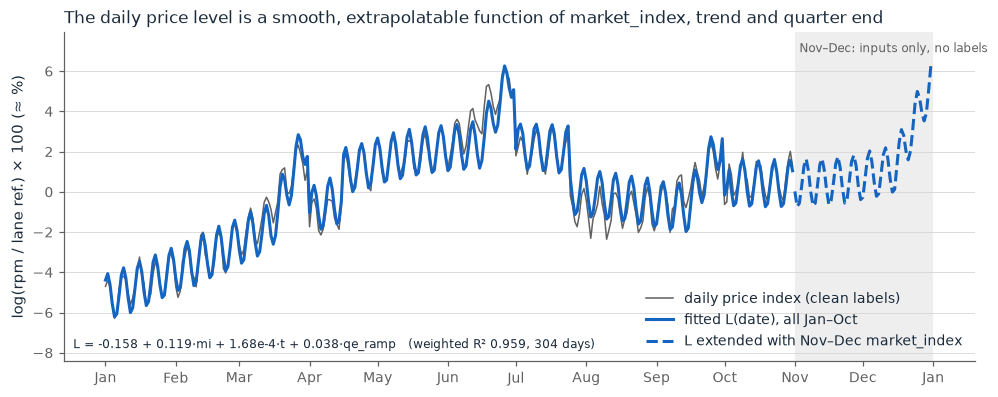

In [18]:
# Figure 9: fitted L vs the daily price index, extended over Nov–Dec with the validation market_index.
days = pd.date_range(config.DATE_ORIGIN, VAL_END, freq="D")
L_all = pd.Series(level.predict_dates(days), index=days)
future = L_all.index >= VAL_START
fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
ax.plot(idx.index, 100 * idx, color=GRAY, lw=1.0, label="daily price index (clean labels)")
ax.plot(L_all.index[~future], 100 * L_all[~future], color=BLUE, lw=2.0, label="fitted L(date), all Jan–Oct")
ax.plot(L_all.index[future], 100 * L_all[future], color=BLUE, lw=2.0, ls="--", label="L extended with Nov–Dec market_index")
shade_validation(ax)
month_axis(ax)
c = level.coef_
ax.text(0.01, 0.03, f"L = {c['const']:+.3f} + {c['mi_day_mean']:.3f}·mi + {1e4 * c['t']:.2f}e-4·t + {c['qe_ramp']:.3f}·qe_ramp"
        f"   (weighted R² {level.r2_:.3f}, {level.n_days_} days)", transform=ax.transAxes, fontsize=8, color=INK, va="bottom")
ax.set_ylabel("log(rpm / lane ref.) × 100 (≈ %)")
ax.set_title("The daily price level is a smooth, extrapolatable function of market_index, trend and quarter end", loc="left")
ax.set_ylim(ax.get_ylim()[0] - 1.5, ax.get_ylim()[1] + 1)
ax.legend(loc="lower right")
plt.show()

In [19]:
ls_ = read_csv("backtest/level_summary.csv").set_index(["experiment", "fold"])
names = ["yardstick_level", "cb_time", "cb_level", "cb_level_mi", "cb_level_noqs", "cb_level_notrend", "cb_level_noramp", "cb_level_k2"]
rows = []
for n in names:
    r = {"experiment": n, "seeds": int(ls_.loc[(n, "F3"), "n_runs"]), "what changes": EXPERIMENTS[n].description}
    for f in ["F1", "F2", "F3"]:
        r[f] = pm(ls_.loc[(n, f), "mae_clean_mean"], ls_.loc[(n, f), "mae_clean_sd"], ls_.loc[(n, f), "n_runs"])
    r["F1+F2"] = ls_.loc[[(n, "F1"), (n, "F2")], "mae_clean_mean"].mean()
    r["F3 MAPE %"] = ls_.loc[(n, "F3"), "mape_clean_mean"]
    rows.append(r)
abl = pd.DataFrame(rows)
show(abl, fmt={"F1+F2": "{:.1f}"}, caption="MAE clean ($), mean ± sd over seeds (backtest/level_summary.csv)")

variants = abl[abl["experiment"].str.startswith("cb_level")]
chosen = variants.loc[variants["F1+F2"].idxmin(), "experiment"]
f3 = {n: ls_.loc[(n, "F3"), "mae_clean_mean"] for n in variants["experiment"]}
f3_best = min(f3, key=f3.get)
sel = abl.set_index("experiment")["F1+F2"]
print(f"selection on F1+F2: {chosen} ({sel[chosen]:.1f}) vs cb_level ({sel['cb_level']:.1f}); "
      f"F3 alone would have picked {f3_best} ({f3[f3_best]:.1f} vs {f3[chosen]:.1f}) — per protocol F3 does not reverse the choice")
print(f"no trend: F3 {f3['cb_level_notrend']:.1f}; no quarter-end ramp: F2 {ls_.loc[('cb_level_noramp', 'F2'), 'mae_clean_mean']:.1f} "
      f"(vs {ls_.loc[('cb_level', 'F2'), 'mae_clean_mean']:.1f} with it)")
takeaway(f"with L owning the level, F1+F2 MAE falls from {sel['cb_time']:.1f} (cb_time) to {sel[chosen]:.1f} ({chosen}), and "
         f"both the trend and the ramp are needed. qs_dev was dropped on F1+F2, although F3 alone would have kept it "
         f"({f3['cb_level']:.1f} vs {f3[chosen]:.1f}).")

experiment,seeds,what changes,F1,F2,F3,F1+F2,F3 MAPE %
yardstick_level,1,"Lane-median rpm x exp(L(date)); L = OLS of daily residuals on [1, mi_day_mean, t, qe_ramp]",82.2,83.3,74.1,82.7,3.13
cb_time,3,E1 + t_days time coordinate,83.1 ± 2.8,67.1 ± 3.0,57.5 ± 1.9,75.1,2.35
cb_level,3,L(date) as CatBoost baseline; trees on cross-sectional features only (K=1),49.4 ± 0.3,60.6 ± 0.5,34.8 ± 0.1,55.0,1.50
cb_level_mi,3,cb_level + mi_day_mean as a tree feature (level x lane interactions),43.9 ± 1.1,62.6 ± 0.7,49.3 ± 0.3,53.2,2.02
cb_level_noqs,2,cb_level without qs_dev,50.6 ± 0.1,50.5 ± 0.5,37.5 ± 0.1,50.6,1.61
cb_level_notrend,2,"cb_level with L = [1, mi_day_mean, qe_ramp] (no trend: 'what if the drift stops')",62.2 ± 0.0,52.0 ± 0.8,83.5 ± 0.5,57.1,3.55
cb_level_noramp,2,"cb_level with L = [1, mi_day_mean, t] (no quarter-end ramp)",46.8 ± 0.2,87.5 ± 0.6,40.1 ± 0.0,67.1,1.71
cb_level_k2,1,"cb_level with K=2 backfitting rounds (L refit on log(rpm) - f(x)), seed 0",40.5,75.6,34.8,58.0,1.50


selection on F1+F2: cb_level_noqs (50.6) vs cb_level (55.0); F3 alone would have picked cb_level (34.8 vs 37.5) — per protocol F3 does not reverse the choice
no trend: F3 83.5; no quarter-end ramp: F2 87.5 (vs 60.6 with it)


**Takeaway: with L owning the level, F1+F2 MAE falls from 75.1 (cb_time) to 50.6 (cb_level_noqs), and both the trend and the ramp are needed. qs_dev was dropped on F1+F2, although F3 alone would have kept it (34.8 vs 37.5).**

## 7. Tuning

**Question.** Once the design is fixed, do the feature set and the CatBoost hyper-parameters still matter?

- **Selection instrument.** Selection uses the **day-debiased MAE**: clean MAE after removing each test day's
  median log error. L's day-level extrapolation error is common to all loads of a day, and no tree parameter
  can fix it, so removing it isolates the cross-sectional error the trees own. It is a selection instrument,
  not a performance number; plain MAE is always shown next to it.
- **Folds.** F1 + F2 only; F3 is shown for information.

In [20]:
abl2 = read_csv("tuning/ablation.csv")
view = pd.DataFrame({
    "masked family": abl2["variant"], "features removed": abl2["dropped"].fillna("–"), "# features": abl2["n_features"],
    "debiased F1": abl2["mae_debiased_F1"], "debiased F2": abl2["mae_debiased_F2"], "debiased F1+F2": abl2["mae_debiased_f12"],
    "Δ debiased": abl2["delta_mae_debiased_f12"], "plain F1+F2": abl2["mae_clean_f12"], "Δ plain": abl2["delta_mae_clean_f12"],
    "debiased F3 (info)": abl2["mae_debiased_F3"]})
show(view, fmt={"Δ debiased": "{:+.2f}", "Δ plain": "{:+.2f}"},
     caption="cb_level_noqs, default params, seed 0: one feature family masked at a time (tuning/ablation.csv)")
gain = -view["Δ debiased"].min()
print(f"largest improvement from dropping a family: ${gain:.2f} (rule: drop only if > $1) → keep all {abl2['n_features'].iloc[0]} features; "
      f"weight is worth ${view.set_index('masked family').loc['weight', 'Δ debiased']:.1f}, coordinates "
      f"${view.set_index('masked family').loc['coords', 'Δ debiased']:.1f}")

masked family,features removed,# features,debiased F1,debiased F2,debiased F1+F2,Δ debiased,plain F1+F2,Δ plain,debiased F3 (info)
full,–,24,34.42,31.43,32.92,+0.00,50.45,+0.00,32.50
city,pickup delivery,22,34.60,31.13,32.87,-0.06,50.54,+0.09,32.31
lane,lane,23,34.46,31.39,32.92,-0.00,50.57,+0.11,32.39
coords,pickup_lat pickup_lon delivery_lat delivery_lon delta_lat delta_lon bearing_deg,17,36.49,33.18,34.84,+1.91,51.76,+1.31,34.14
crowfly,haversine_mi circuity,22,34.47,31.20,32.83,-0.09,50.44,-0.02,32.43
weight,weight weight_missing weight_was_negative weight_at_cap weight_at_floor,19,60.81,58.22,59.51,+26.59,70.49,+20.03,59.44
dow_dom,dow dom,22,35.05,31.40,33.23,+0.30,50.82,+0.37,33.07
mi_dev,mi_dev mi_missing,22,34.90,31.78,33.34,+0.41,50.58,+0.13,32.98


largest improvement from dropping a family: $0.09 (rule: drop only if > $1) → keep all 24 features; weight is worth $26.6, coordinates $1.9


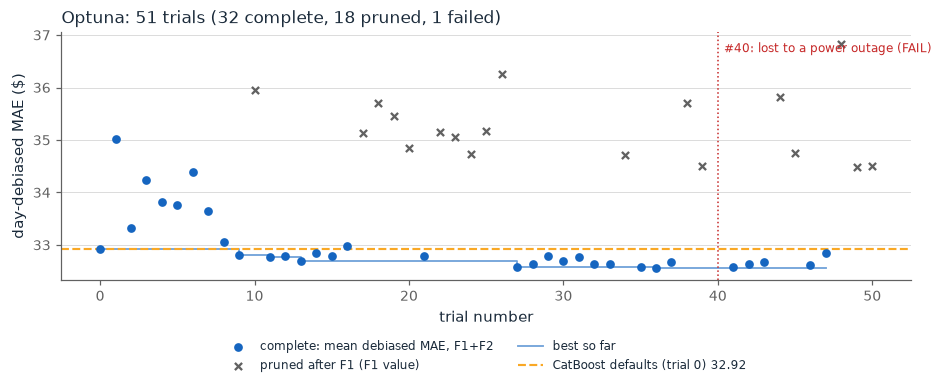

trial #40 ran 834.2 min (the outage); all other trials took 75.2 min


In [21]:
# Figure 10: Optuna trials (TPE + median pruner on F1 as step 0).
trials = read_csv("tuning/trials.csv")
done = trials[trials["state"] == "COMPLETE"]
pruned = trials[trials["state"] == "PRUNED"]
failed = trials[trials["state"] == "FAIL"]
best_so_far = done.set_index("number")["value"].cummin()
default_value = trials.loc[trials["user_attrs_is_default"] == True, "value"].iloc[0]  # noqa: E712

fig, ax = plt.subplots(figsize=(8.5, 3.4), layout="constrained")
ax.scatter(done["number"], done["value"], color=BLUE, s=22, label="complete: mean debiased MAE, F1+F2", zorder=3)
ax.scatter(pruned["number"], pruned["value"], color=GRAY, marker="x", s=22, label="pruned after F1 (F1 value)", zorder=3)
ax.step(best_so_far.index, best_so_far, where="post", color=BLUE, lw=1.2, alpha=0.6, label="best so far")
ax.axhline(default_value, color=AMBER, lw=1.4, ls="--", label=f"CatBoost defaults (trial 0) {default_value:.2f}")
for n in failed["number"]:
    ax.axvline(n, color=RED, lw=1, ls=":")
    ax.text(n + 0.4, 0.96, f"#{n}: lost to a power outage (FAIL)", transform=ax.get_xaxis_transform(),
            color=RED, fontsize=8, va="top")
ax.set_xlabel("trial number")
ax.set_ylabel("day-debiased MAE ($)")
ax.set_title(f"Optuna: {len(trials)} trials ({len(done)} complete, {len(pruned)} pruned, {len(failed)} failed)", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=2, fontsize=8)
plt.show()
outage_min = failed["duration_s"].sum() / 60
print(f"trial #{failed['number'].iloc[0]} ran {outage_min:.1f} min (the outage); all other trials took "
      f"{(trials['duration_s'].sum() - failed['duration_s'].sum()) / 60:.1f} min")

In [22]:
reeval = read_csv("tuning/reeval.csv")
params = reeval["params"].map(json.loads)
view = pd.DataFrame({
    "candidate": reeval["candidate"], "depth": params.map(lambda p: p["depth"]),
    "learning rate": params.map(lambda p: p["learning_rate"]), "iterations": params.map(lambda p: p["iterations"]),
    "bootstrap": params.map(lambda p: p["bootstrap_type"]),
    "debiased F1+F2": [pm(m, s, 3, 2) for m, s in zip(reeval["mae_debiased_f12_mean"], reeval["mae_debiased_f12_sd"])],
    "plain clean F1+F2": reeval["mae_clean_f12_mean"], "fit s / fold": reeval["fit_seconds_f12"]})
show(view, fmt={"learning rate": "{:.3f}", "fit s / fold": "{:.1f}"},
     caption="Defaults and the top-5 trials re-run with seeds 0–2 on F1+F2 (tuning/reeval.csv)")

best = read_json("tuning/best_params.json")
sel = best["selection"]
cand = pd.DataFrame(sel["candidates"]).set_index("candidate")
top, dflt = cand.drop("default")["mae_debiased_f12_mean"].idxmin(), cand.loc["default"]
d_debiased = dflt["mae_debiased_f12_mean"] - cand.loc[top, "mae_debiased_f12_mean"]
d_plain = dflt["mae_clean_f12_mean"] - cand.loc[top, "mae_clean_f12_mean"]
print(f"rule: {sel['rule']}")
print(f"best tuned ({top}) beats the defaults by ${d_debiased:.2f} debiased ({d_debiased / dflt['mae_debiased_f12_mean']:.1%}) and "
      f"${d_plain:.2f} plain ({d_plain / dflt['mae_clean_f12_mean']:.1%}); it fits "
      f"{cand.loc[top, 'fit_seconds_f12'] / dflt['fit_seconds_f12']:.1f}× slower → chosen: {sel['chosen']}")

fc = read_csv("tuning/final_comparison.csv").set_index(["experiment", "fold"])
mape_time = ls_.loc[("cb_time", "F3"), "mape_clean_mean"]
mape_final = fc.loc[("cb_level_tuned", "F3"), "mape_clean_mean"]
takeaway(f"the decomposition mattered (F3 MAPE {mape_time:.2f}% for cb_time → {mape_final:.2f}% for the final design). "
         f"Hyper-parameters moved plain F1+F2 MAE by only {d_plain / dflt['mae_clean_f12_mean']:.1%}, inside the $0.5 tie "
         f"and at ~{cand.loc[top, 'fit_seconds_f12'] / dflt['fit_seconds_f12']:.0f}× the fit time, so the CatBoost "
         f"defaults are kept.")

candidate,depth,learning rate,iterations,bootstrap,debiased F1+F2,plain clean F1+F2,fit s / fold
trial_36,8,0.021,"3,500",Bernoulli,32.57 ± 0.06,50.53,65.5
trial_41,8,0.021,"3,100",Bernoulli,32.57 ± 0.05,50.58,64.7
trial_46,8,0.026,"2,400",Bernoulli,32.63 ± 0.07,50.61,44.4
trial_27,6,0.059,"3,800",MVS,32.64 ± 0.08,50.61,50.3
trial_35,8,0.021,"3,800",MVS,32.65 ± 0.06,50.58,81.6
default,6,0.050,"2,000",MVS,32.91 ± 0.05,50.63,23.7


rule: re-evaluate the defaults and the top trials with seeds [0, 1, 2] on F1+F2; best mean day-debiased MAE, ties within $0.5 broken by fit time
best tuned (trial_36) beats the defaults by $0.34 debiased (1.0%) and $0.10 plain (0.2%); it fits 2.8× slower → chosen: default


**Takeaway: the decomposition mattered (F3 MAPE 2.35% for cb_time → 1.61% for the final design). Hyper-parameters moved plain F1+F2 MAE by only 0.2%, inside the $0.5 tie and at ~3× the fit time, so the CatBoost defaults are kept.**

## 8. Final F3 results

**Question.** How good is the chosen design on the untouched holdout (train Jan–Aug → test Sep–Oct), and where
is it weak?

The final configuration is `cb_level_noqs` with the default CatBoost parameters. In the files it is called
`cb_level_tuned`, because it reads `best_params.json`, which holds the defaults. The 5-seed ensemble mirrors
the final fit and is for information only.

In [23]:
ens = read_json("final/ensemble_f3.json")
num = fc.select_dtypes("number").columns
print("cb_level_tuned reproduces cb_level_noqs run for run:",
      np.allclose(fc.loc["cb_level_tuned", num].to_numpy(), fc.loc["cb_level_noqs", num].to_numpy()))

def row(label, src, name):
    r = {"model": label, "seeds": int(src.loc[(name, "F3"), "n_runs"])}
    for f in ["F1", "F2", "F3"]:
        r[f"{f} MAE clean"] = pm(src.loc[(name, f), "mae_clean_mean"], src.loc[(name, f), "mae_clean_sd"], src.loc[(name, f), "n_runs"])
    r["F3 MAE all"] = src.loc[(name, "F3"), "mae_all_mean"]
    r["F3 MAPE %"] = src.loc[(name, "F3"), "mape_clean_mean"]
    r["F3 debiased"] = src.loc[(name, "F3"), "mae_debiased_mean"] if "mae_debiased_mean" in src.columns else np.nan
    return r

comp = pd.DataFrame([
    row("yardstick (lane median rpm × distance)", ls_, "yardstick"),
    row("yardstick_level (reference × exp(L))", fc, "yardstick_level"),
    row("cb_time (phase-1 trees + t_days)", ls_, "cb_time"),
    row("cb_level (with qs_dev; not selected)", fc, "cb_level"),
    row("cb_level_noqs — FINAL (default params)", fc, "cb_level_tuned"),
    {"model": "final, 5-seed ensemble (info)", "seeds": len(ens["seeds"]), "F1 MAE clean": "–", "F2 MAE clean": "–",
     "F3 MAE clean": f"{ens['ensemble']['mae_clean']:.2f}", "F3 MAE all": ens["ensemble"]["mae_all"],
     "F3 MAPE %": ens["ensemble"]["mape_clean"], "F3 debiased": ens["ensemble"]["mae_debiased"]}])
show(comp, fmt={"F3 MAE all": "{:.1f}", "F3 debiased": "{:.1f}"}, caption="MAE in $, mean ± sd over seeds")
print(f"ensemble vs single seeds 0–4 on F3: {ens['ensemble']['mae_clean']:.2f} vs "
      f"{ens['single_seed_mae_clean_mean']:.2f} ± {ens['single_seed_mae_clean_sd']:.2f}")

cb_level_tuned reproduces cb_level_noqs run for run: True


model,seeds,F1 MAE clean,F2 MAE clean,F3 MAE clean,F3 MAE all,F3 MAPE %,F3 debiased
yardstick (lane median rpm × distance),1,148.8,83.8,76.2,131.7,3.21,–
yardstick_level (reference × exp(L)),1,82.2,83.3,74.1,129.6,3.13,71.7
cb_time (phase-1 trees + t_days),3,83.1 ± 2.8,67.1 ± 3.0,57.5 ± 1.9,113.3,2.35,–
cb_level (with qs_dev; not selected),3,49.4 ± 0.3,60.6 ± 0.5,34.8 ± 0.1,90.9,1.50,29.4
cb_level_noqs — FINAL (default params),3,50.7 ± 0.2,50.5 ± 0.4,37.5 ± 0.1,93.5,1.61,32.6
"final, 5-seed ensemble (info)",5,–,–,37.19,93.2,1.60,32.4


ensemble vs single seeds 0–4 on F3: 37.19 vs 37.38 ± 0.13


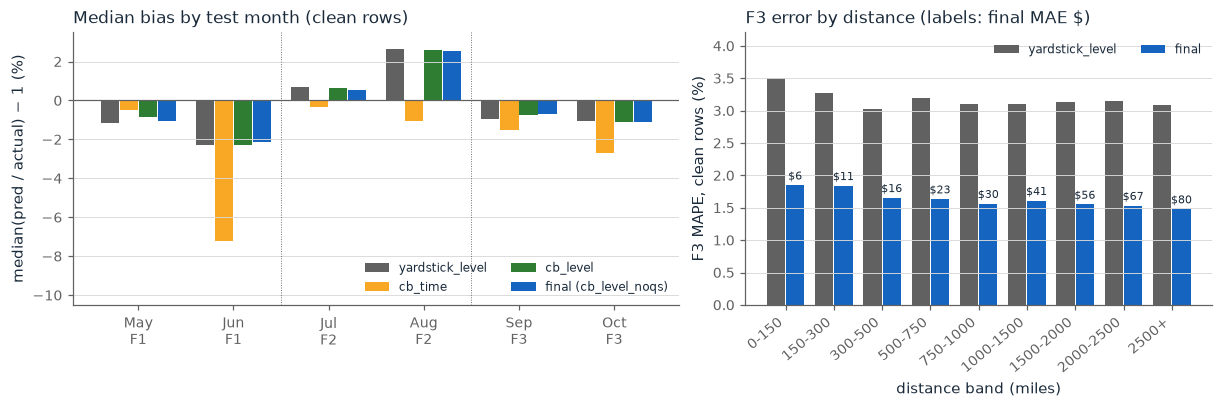

In [24]:
# Figure 11: month bias per test month (left) and F3 MAPE by distance band (right).
fmb = read_csv("tuning/final_month_bias.csv").groupby(["experiment", "month"])["median_bias_clean"].mean()
bias_series = {"yardstick_level": (GRAY, fmb["yardstick_level"]), "cb_time": (AMBER, month_bias("cb_time").set_index("month")["bias"]),
               "cb_level": (GREEN, fmb["cb_level"]), "final (cb_level_noqs)": (BLUE, fmb["cb_level_tuned"])}
slices = read_csv("tuning/final_slices_f3.csv")
bands = slices[(slices["slice"] == "distance_band")].pivot(index="group", columns="experiment", values="mape_mean")
band_mae = slices[(slices["slice"] == "distance_band") & (slices["experiment"] == "cb_level_tuned")].set_index("group")["mae_mean"]
band_order = sorted(bands.index, key=lambda s: float(s.split("-")[0].rstrip("+")))

fig, (ax, axb) = plt.subplots(1, 2, figsize=(11, 3.6), width_ratios=[1.3, 1], layout="constrained")
months = sorted(fmb["cb_level_tuned"].index)
x = np.arange(len(months))
for k, (name, (col, s)) in enumerate(bias_series.items()):
    ax.bar(x + (k - 1.5) * 0.2, 100 * s.reindex(months).to_numpy(), width=0.19, color=col, label=name)
ax.axhline(0, color=GRAY, lw=0.8)
for b in (1.5, 3.5):
    ax.axvline(b, color=GRAY, lw=0.6, ls=":")
ax.set_xticks(x, [f"{MONTHS[int(m[-2:]) - 1]}\n{f.name}" for m, f in zip(months, [g for g in get_folds() for _ in (0, 1)])])
ax.set_ylabel("median(pred / actual) − 1 (%)")
ax.set_title("Median bias by test month (clean rows)", loc="left")
ax.set_ylim(-10.5, 3.5)
ax.legend(loc="lower right", fontsize=8, ncols=2)
xb = np.arange(len(band_order))
axb.bar(xb - 0.2, bands.loc[band_order, "yardstick_level"], width=0.38, color=GRAY, label="yardstick_level")
bars = axb.bar(xb + 0.2, bands.loc[band_order, "cb_level_tuned"], width=0.38, color=BLUE, label="final")
axb.bar_label(bars, labels=[f"${band_mae[b]:.0f}" for b in band_order], fontsize=7, padding=2)
axb.set_xticks(xb, band_order, rotation=40, ha="right")
axb.set_xlabel("distance band (miles)")
axb.set_ylabel("F3 MAPE, clean rows (%)")
axb.set_title("F3 error by distance (labels: final MAE $)", loc="left")
axb.set_ylim(0, bands.to_numpy().max() * 1.2)
axb.legend(loc="upper right", fontsize=8, ncols=2)
plt.show()

In [25]:
eq = slices[slices["slice"] == "equipment"].pivot(index="group", columns="experiment", values=["mape_mean", "mae_mean", "median_bias_mean"])
eq_n = slices[(slices["slice"] == "equipment") & (slices["experiment"] == "cb_level_tuned")].set_index("group")["n"].astype(int)
eq_view = pd.DataFrame({"equipment": eq.index, "n (F3 clean)": eq_n.loc[eq.index].to_numpy(),
                        "final MAE $": eq[("mae_mean", "cb_level_tuned")].to_numpy(),
                        "final MAPE %": eq[("mape_mean", "cb_level_tuned")].to_numpy(),
                        "final median bias %": 100 * eq[("median_bias_mean", "cb_level_tuned")].to_numpy(),
                        "yardstick_level MAPE %": eq[("mape_mean", "yardstick_level")].to_numpy()})
show(eq_view, fmt={"final MAE $": "{:.1f}", "final median bias %": "{:+.2f}"}, caption="F3 by equipment (tuning/final_slices_f3.csv)")

cold_p1 = summary[(summary["experiment"] == "cb_cold_start") & summary["fold"].str.startswith("F3")]
cold = ls_.loc[("cb_level_cold", "F3")]
show(pd.DataFrame({
    "design": ["phase 1 (cb_base trees)", "final design (cb_level)"],
    "city draws": [len(cold_p1), int(cold["n_runs"])],
    "MAE clean, cold rows": [cold_p1["mae_clean_cold"].mean(), cold["mae_clean_cold_mean"]],
    "MAE clean, warm rows": [cold_p1["mae_clean_warm"].mean(), cold["mae_clean_warm_mean"]],
    "MAE clean, all": [cold_p1["mae_clean"].mean(), cold["mae_clean_mean"]]}),
    fmt={c: "{:.1f}" for c in ["MAE clean, cold rows", "MAE clean, warm rows", "MAE clean, all"]},
    caption="Cold-start slice on F3: 8 random cities removed from training; 'cold' = test rows touching them")
final_f3 = fc.loc[("cb_level_tuned", "F3")]
band_mape = bands["cb_level_tuned"]
worst = eq_view.loc[eq_view["final MAPE %"].idxmax()]
takeaway(f"on F3 the final design scores MAE ${final_f3['mae_clean_mean']:.1f} (MAPE {final_f3['mape_clean_mean']:.2f}%), half the "
         f"level-aware yardstick's ${fc.loc[('yardstick_level', 'F3'), 'mae_clean_mean']:.1f}. The error is a flat {band_mape.min():.1f}–{band_mape.max():.1f}% "
         f"of the rate across distance bands; {worst['equipment']} is the weakest segment ({worst['final MAPE %']:.2f}%); unseen "
         f"cities cost ≈ ${cold['mae_clean_cold_mean'] - cold['mae_clean_warm_mean']:.0f} per load.")

equipment,n (F3 clean),final MAE $,final MAPE %,final median bias %,yardstick_level MAPE %
Dry Van,"5,275",33.4,1.52,-0.73,3.03
Flatbed,"1,746",47.6,1.97,-1.46,3.35
Reefer,"2,358",39.1,1.55,-1.00,3.20


design,city draws,"MAE clean, cold rows","MAE clean, warm rows","MAE clean, all"
phase 1 (cb_base trees),2,94.0,90.7,91.1
final design (cb_level),2,40.3,34.4,35.6


**Takeaway: on F3 the final design scores MAE $37.5 (MAPE 1.61%), half the level-aware yardstick's $74.1. The error is a flat 1.5–1.8% of the rate across distance bands; Flatbed is the weakest segment (1.97%); unseen cities cost ≈ $6 per load.**

## 9. Final predictions and sanity checks

**Question.** Do the Nov–Dec predictions continue the history plausibly, and do they behave well on the
unusual rows?

The daily price index is recomputed here from `validation_predictions.csv` (predictions, Nov–Dec) and the
training labels (Jan–Oct). Both use the same all-data lane reference, so the two parts of the curve are
directly comparable.

12,000 rows; same load_id order as the template: True; NaN 0; min $188.86, median $2,068.84, max $7,033.20


month,source,mean index %,mean L %,days 25+ minus days 1–15 (%)
2025-03,actual,-0.43,-0.76,+3.14
2025-06,actual,+3.89,+3.21,+2.60
2025-08,actual,-1.00,-0.34,-0.04
2025-09,actual,+0.37,+0.14,+1.94
2025-10,actual,+0.61,+0.41,+0.23
2025-11,predicted,+0.46,+0.47,+0.42
2025-12,predicted,+2.32,+2.20,+3.41


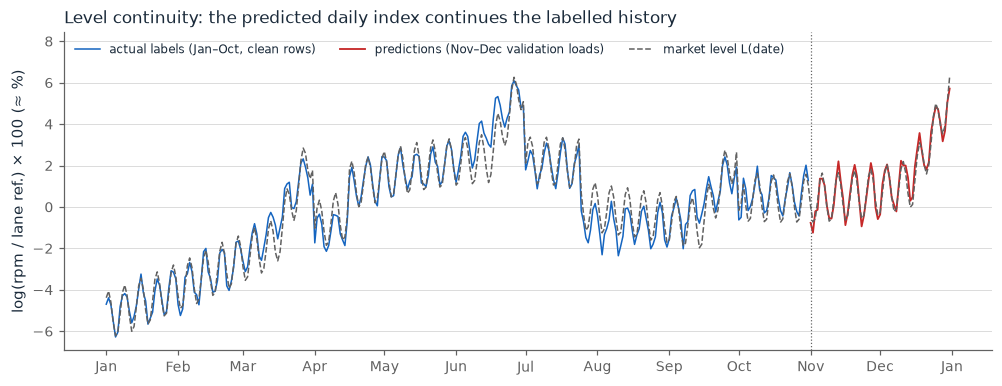

In [26]:
preds = pd.read_csv(ROOT / "validation_predictions.csv")
template = pd.read_csv(config.TEMPLATE_PATH)
val = clean(val_raw).merge(preds, on="load_id", how="left", validate="one_to_one")
print(f"{len(preds):,} rows; same load_id order as the template: {preds['load_id'].equals(template['load_id'])}; "
      f"NaN {preds['predicted_rate'].isna().sum()}; min ${preds['predicted_rate'].min():,.2f}, "
      f"median ${preds['predicted_rate'].median():,.2f}, max ${preds['predicted_rate'].max():,.2f}")

val_ref = reference.reference_rpm(val)
pred_log_ratio = np.log(val["predicted_rate"] / val["distance"] / val_ref)
pred_idx = pred_log_ratio.groupby(val["date"]).mean()
both = pd.concat([idx, pred_idx])

def month_mean(s, m):
    return s[s.index.to_period("M") == pd.Period(m)].mean()

def late_lift(s, m):
    s = s[s.index.to_period("M") == pd.Period(m)]
    return s[s.index.day >= 25].mean() - s[s.index.day <= 15].mean()

cont = pd.DataFrame([{"month": m, "source": "predicted" if pd.Period(m) >= VAL_START.to_period("M") else "actual",
                      "mean index %": 100 * month_mean(both, m), "mean L %": 100 * month_mean(L_all, m),
                      "days 25+ minus days 1–15 (%)": 100 * late_lift(both, m)}
                     for m in ["2025-03", "2025-06", "2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]])
show(cont, fmt={c: "{:+.2f}" for c in cont.columns[2:]}, caption="Daily index: Mar / Jun / Sep / Dec are quarter-end months")

# Figure 12: level continuity.
fig, ax = plt.subplots(figsize=(9, 3.4), layout="constrained")
ax.plot(idx.index, 100 * idx, color=BLUE, lw=1.0, label="actual labels (Jan–Oct, clean rows)")
ax.plot(pred_idx.index, 100 * pred_idx, color=RED, lw=1.2, label="predictions (Nov–Dec validation loads)")
ax.plot(L_all.index, 100 * L_all, color=GRAY, lw=1.0, ls="--", label="market level L(date)")
ax.axvline(VAL_START, color=GRAY, lw=0.8, ls=":")
month_axis(ax)
ax.set_ylabel("log(rpm / lane ref.) × 100 (≈ %)")
ax.set_title("Level continuity: the predicted daily index continues the labelled history", loc="left")
ax.legend(loc="upper left", ncols=3, fontsize=8)
ax.set_ylim(top=ax.get_ylim()[1] + 1.5)
plt.show()

In [27]:
# Agreement with yardstick_level (lane reference × exp(L), all Jan–Oct; no trees) -- recomputed with the package.
yard = LaneLevelBaseline(market).fit(clean_rows, reference).predict(val)
ratio = val["predicted_rate"].to_numpy() / yard
r_rates = np.corrcoef(val["predicted_rate"], yard)[0, 1]
big = np.abs(ratio - 1) > 0.10
print(f"vs yardstick_level: r = {r_rates:.4f} (rates); median ratio {np.median(ratio):.4f}; "
      f"5–95% of ratio {np.quantile(ratio, 0.05):.3f}–{np.quantile(ratio, 0.95):.3f}; |ratio − 1| > 10%: {big.sum()} rows ({big.mean():.2%})")

# Unseen cities and edge cases: tables from artifacts/final/sanity.md (scripts/sanity.py, which needs the saved models).
sanity_path = ART / "final" / "sanity.md"
cities = md_tables(md_section(sanity_path, 3))[1]
show(cities, fmt={c: "{:.3f}" for c in ["rel rpm", "rel rpm outbound", "rel rpm inbound"]},
     caption="Unseen cities: median predicted rpm relative to warm rows of the same equipment × band (sanity.md §3)")
warm_range = re.search(r"Warm cities span ([\d.]+)–([\d.]+)", md_section(sanity_path, 3)).groups()
print(f"warm cities span {warm_range[0]}–{warm_range[1]}; all unseen cities inside: {bool(cities['inside warm range'].eq('True').all())}")
edges_tab = md_tables(md_section(sanity_path, 5))[0]
show(edges_tab, fmt={c: "{:.4f}" for c in edges_tab.columns if "/" in c},
     caption="Edge cases: median ratios per group; 'actual / yardstick' is the same quantity on Jan–Oct labels (sanity.md §5)")
e = edges_tab.set_index("group")
takeaway(f"the predicted Nov level ({100 * month_mean(pred_idx, '2025-11'):+.2f}%) continues October's "
         f"({100 * month_mean(idx, '2025-10'):+.2f}%), and December shows the expected quarter-end lift "
         f"({100 * late_lift(pred_idx, '2025-12'):+.2f}%). Predictions track yardstick_level (r = {r_rates:.3f}). Unseen "
         f"cities sit inside the warm-city range, and edge cases mirror history (capped weight "
         f"{e.loc['weight at cap (47,500)', 'pred / yardstick']:.3f} vs {e.loc['weight at cap (47,500)', 'actual / yardstick (in-sample)']:.3f}).")

vs yardstick_level: r = 0.9979 (rates); median ratio 1.0016; 5–95% of ratio 0.947–1.055; |ratio − 1| > 10%: 43 rows (0.36%)


city,n,rel rpm,rel rpm outbound,rel rpm inbound,inside warm range
Allentown,171,0.988,0.989,0.987,True
Charlotte,176,0.996,0.996,0.995,True
Chicago,179,0.982,0.984,0.982,True
Jackson,193,1.031,1.042,1.019,True
Knoxville,170,1.007,1.006,1.008,True
Laredo,195,1.024,1.024,1.024,True
Norfolk,172,0.990,0.993,0.988,True
San Diego,191,1.003,1.001,1.006,True


warm cities span 0.969–1.036; all unseen cities inside: True


group,n val,pred rpm / ref rpm,pred / yardstick,n Jan–Oct clean,actual / yardstick (in-sample)
all rows,"12,000",1.0143,1.0016,"47,323",1.0000
"weight at cap (47,500)",301,1.0459,1.0334,"1,188",1.0285
"weight at floor (5,000)",7,0.9711,0.9598,32,0.9633
weight negative (flipped),145,1.0134,1.0010,283,1.0035
weight missing,165,1.0102,0.9969,297,0.9999
market_index missing,249,1.0152,1.0035,368,0.9997


**Takeaway: the predicted Nov level (+0.46%) continues October's (+0.61%), and December shows the expected quarter-end lift (+3.41%). Predictions track yardstick_level (r = 0.998). Unseen cities sit inside the warm-city range, and edge cases mirror history (capped weight 1.033 vs 1.028).**

## 10. The December chart

**Question.** What does the model predict for Lexington → Fort Wayne (Dry Van, 360 mi, 32,000 lb) for each day
of December, and why that shape?

- **Missing inputs.** The chart file has no `market_index` or `quote_signal`.
- **Option A, the deliverable.** Each date gets that day's market-wide mean market_index, averaged over the
  December validation loads. These are **inputs, not labels**, so the chart load is priced as a typical load of
  that day.
- **Neutral market, the sanity arm.** Every December day gets the December-average market_index, which removes
  the weekly wave.

deliverable = rounded Option A: max |Δ| $0.0050; L rebuilt from the model card: max |Δ| 4.9e-07


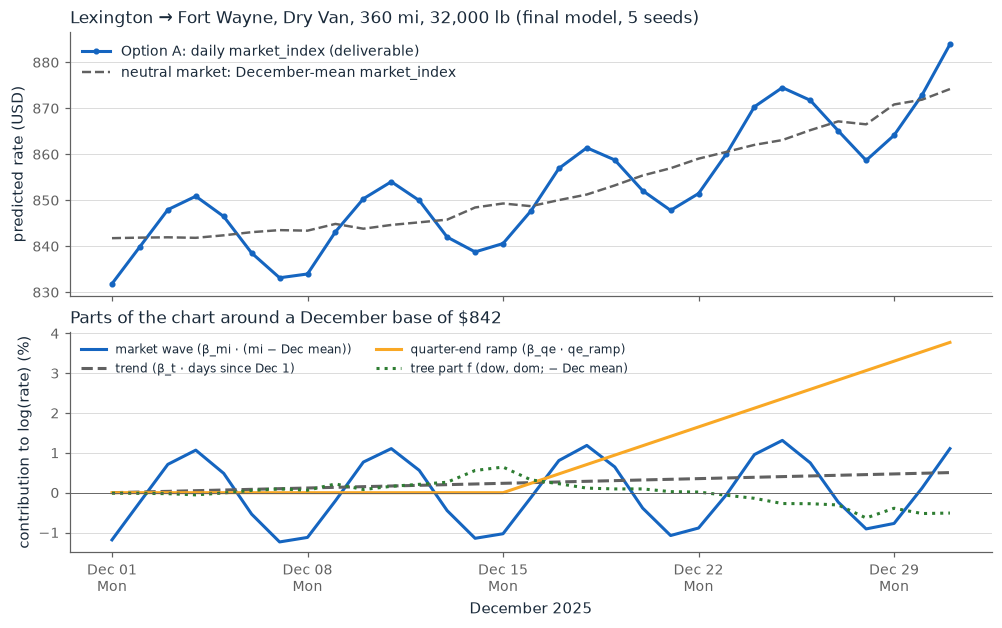

Option A: $831.84 (Mon Dec 01) – $883.92 (Wed Dec 31), mean $852.88; neutral mean $852.84; max |A − neutral| $11.41
weekly wave (A / neutral − 1): Thu +1.18%, Sun -1.09%; neutral Dec 25–31 vs Dec 1–15: +2.88%; qe_ramp alone lifts Dec 31 by +3.85%; seed sd of f ≤ 0.0031 log


In [28]:
comp_dec = read_csv("final/december_components.csv", parse_dates=["date"])
deliv = pd.read_csv(ROOT / "december_chart_predictions.csv", parse_dates=["date"])
b = pd.Series(card["level"]["coefficients"])
tt = t_days(comp_dec["date"])
L_rebuilt = b["const"] + b["mi_day_mean"] * comp_dec["mi_day_mean"] + b["t"] * tt + b["qe_ramp"] * comp_dec["qe_ramp"]
print(f"deliverable = rounded Option A: max |Δ| ${np.abs(deliv['predicted_rate'] - comp_dec['pred_optionA']).max():.4f}; "
      f"L rebuilt from the model card: max |Δ| {np.abs(L_rebuilt - comp_dec['L']).max():.1e}")

# Decomposition of log(rate) around a December base: market wave + trend + quarter-end ramp + tree part.
parts = pd.DataFrame({
    "market wave (β_mi · (mi − Dec mean))": (b["mi_day_mean"] * (comp_dec["mi_day_mean"] - comp_dec["mi_day_mean"].mean())).to_numpy(),
    "trend (β_t · days since Dec 1)": b["t"] * (tt - tt[0]),
    "quarter-end ramp (β_qe · qe_ramp)": (b["qe_ramp"] * comp_dec["qe_ramp"]).to_numpy(),
    "tree part f (dow, dom; − Dec mean)": (comp_dec["tree_f"] - comp_dec["tree_f"].mean()).to_numpy()},
    index=pd.DatetimeIndex(comp_dec["date"]))
base = 360 * np.exp(b["const"] + b["mi_day_mean"] * comp_dec["mi_day_mean"].mean() + b["t"] * tt[0] + comp_dec["tree_f"].mean())
assert np.allclose(base * np.exp(parts.sum(axis=1)).to_numpy(), comp_dec["pred_optionA"].to_numpy(), rtol=1e-4)

# Figure 13: Option A vs neutral (top) and the parts in % (bottom).
fig, (ax, axp) = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True, height_ratios=[1.2, 1], layout="constrained")
d = comp_dec["date"]
ax.plot(d, comp_dec["pred_optionA"], color=BLUE, lw=2, marker="o", ms=3, label="Option A: daily market_index (deliverable)")
ax.plot(d, comp_dec["pred_neutral"], color=GRAY, lw=1.6, ls="--", label="neutral market: December-mean market_index")
ax.set_ylabel("predicted rate (USD)")
ax.set_title("Lexington → Fort Wayne, Dry Van, 360 mi, 32,000 lb (final model, 5 seeds)", loc="left")
ax.legend(loc="upper left")
styles = [(BLUE, "-"), (GRAY, "--"), (AMBER, "-"), (GREEN, ":")]
for (col, ls), name in zip(styles, parts.columns):
    axp.plot(parts.index, 100 * parts[name], color=col, ls=ls, lw=2, label=name)
axp.axhline(0, color=GRAY, lw=0.6)
axp.set_ylabel("contribution to log(rate) (%)")
axp.set_title(f"Parts of the chart around a December base of ${base:.0f}", loc="left")
axp.legend(loc="upper left", fontsize=8, ncols=2)
axp.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
axp.xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%a"))
axp.set_xlabel("December 2025")
plt.show()

a, n = comp_dec["pred_optionA"], comp_dec["pred_neutral"]
wave = (a / n - 1).groupby(d.dt.dayofweek).mean()
early, late = n[d.dt.day <= 15].mean(), n[d.dt.day >= 25].mean()
print(f"Option A: ${a.min():.2f} ({d[a.idxmin()]:%a %b %d}) – ${a.max():.2f} ({d[a.idxmax()]:%a %b %d}), mean ${a.mean():.2f}; "
      f"neutral mean ${n.mean():.2f}; max |A − neutral| ${np.abs(a - n).max():.2f}")
print(f"weekly wave (A / neutral − 1): Thu {pct(wave[3])}, Sun {pct(wave[6])}; neutral Dec 25–31 vs Dec 1–15: {pct(late / early - 1)}; "
      f"qe_ramp alone lifts Dec 31 by {pct(np.expm1(b['qe_ramp']))}; seed sd of f ≤ {comp_dec['tree_f_seed_sd'].max():.4f} log")

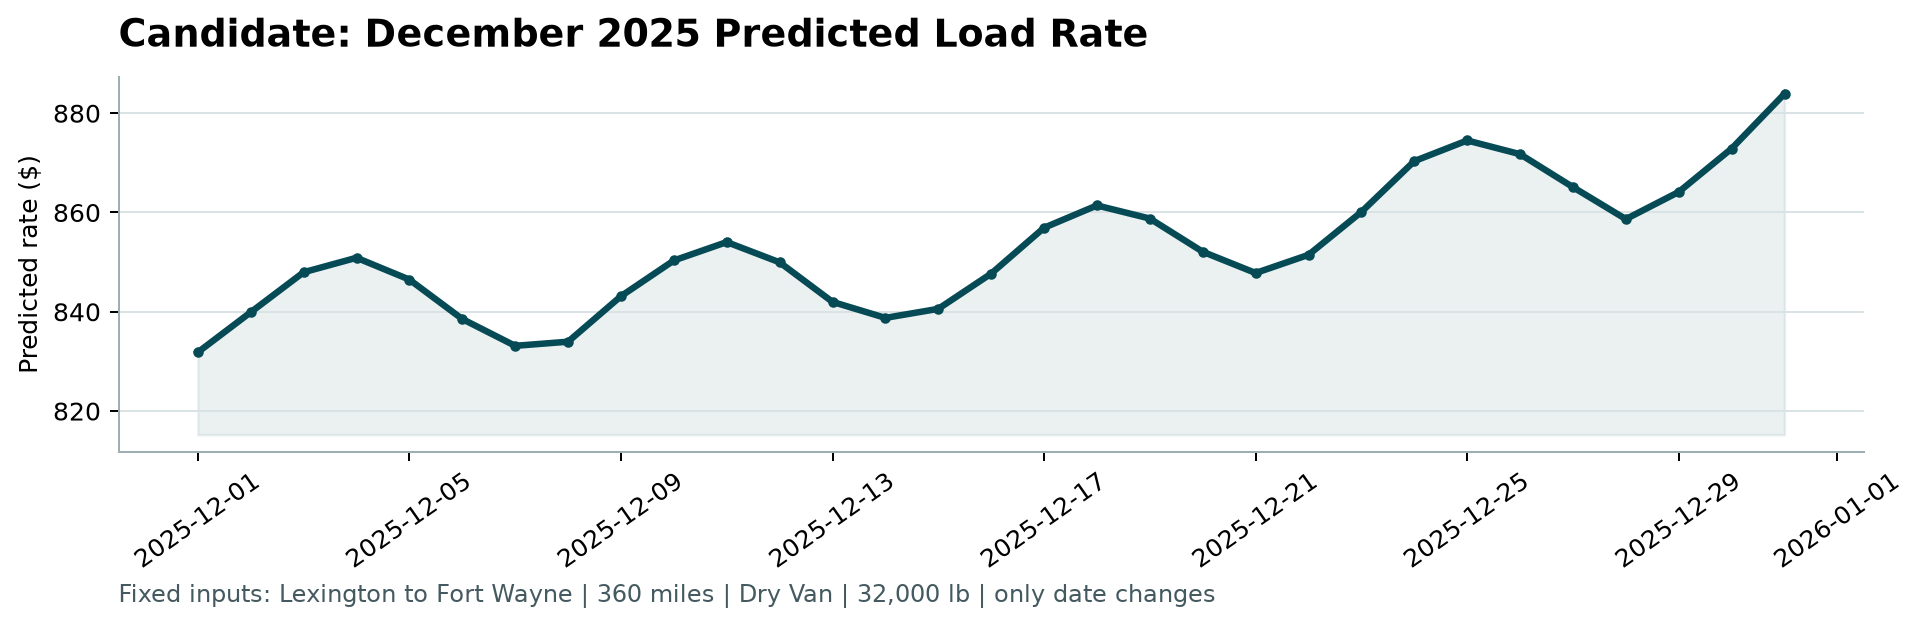

In [29]:
display(Image(filename=str(ROOT / "scorer_results" / "candidate_december.png"), width=820))

**Why Option A is defensible.**
- **Frozen weights.** L's coefficients and the trees are fitted on labels up to **Oct 31** and then frozen.
- **Inputs only.** December enters only through **inputs**: the day's market_index, which the validation file
  supplies for every December date, and the calendar. No validation label exists or is used.
- **Same as production.** This is how the model would run live: yesterday's weights, today's market reading.
  The chart is priced exactly like any validation load of the same day. `sanity.md` §6 shows that the December
  Lexington → Fort Wayne validation loads, set to the chart's inputs, reproduce the chart value exactly.
- **Bounded market effect.** The neutral-market curve bounds how much of the shape comes from market_index.
  The trend, the quarter-end ramp and the trees are identical in both arms.

In [30]:
takeaway(f"the chart runs from ${a.min():.0f} to ${a.max():.0f} (mean ${a.mean():.0f}): a weekly market wave "
         f"(Thu {pct(wave[3], 1)}, Sun {pct(wave[6], 1)}) riding on the trend and a late-December quarter-end ramp. "
         f"The neutral arm stays within ${np.abs(a - n).max():.0f} of it with the same mean.")

**Takeaway: the chart runs from $832 to $884 (mean $853): a weekly market wave (Thu +1.2%, Sun -1.1%) riding on the trend and a late-December quarter-end ramp. The neutral arm stays within $11 of it with the same mean.**

## 11. TabPack: a tabular deep-learning check

**Question.** Is the cross-sectional learner the bottleneck? Would a stronger tabular learner beat CatBoost under
the same protocol?

- **What TabPack is.** A packed ensemble of 64 MLPs with randomly sampled hyper-parameters, trained in parallel,
  with periodic numerical embeddings, the Muon optimiser, early stopping per model and greedy online ensemble
  selection on a validation split (Gorishniy et al., *TabPack: Efficient Hyperparameter Ensembles for Tabular Deep
  Learning*, ICML 2026, arXiv:2607.05380).
- **Setup.** The paper's configuration (64 models, `d_block` 384, bf16, patience 16 per model and 32 for the
  ensemble, at most 32 members), seeds 0–2, the same forward-time folds and metric code. TabPack's inner
  validation is the last 4 weeks of each training window, which its network does not train on.
- **Experiments.** `tp_level`: TabPack in CatBoost's slot, on log(rpm) − L(date) with the 24 tree features minus
  `lane`. `tp_standalone`: raw log(rpm) without L, on the phase-1 `cb_time` features. Lane variants: dropped
  (`tp_level`), top-155 (`tp_level_lanetopk`) and full one-hot (`tp_level_lanefull`).
- **Rule.** A blend `w · log p_CB + (1 − w) · log p_TP` is chosen on F1+F2 clean MAE and replaces CatBoost only if
  it gains more than $0.5; F3 is scored once.
- **Compute.** The laptop GPU could not run the plan, so the 36 runs took 38 minutes on a rented RTX 5090 (0.5–2
  min per run); a CPU run is possible but slow. Code and the remote recipe: `scripts/tabpack/`; every number:
  `artifacts/RESULTS.md` §7.

In [31]:
# TabPack vs CatBoost per fold (tabpack/table_a.csv; the CatBoost rows are re-scored from the backtest
# predictions with the same metric code).
tpa = read_csv("tabpack/table_a.csv").set_index(["experiment", "fold"])
tp_models = {"cb_level_noqs": "log rpm − L (chosen CatBoost)", "tp_standalone": "log rpm, no L",
             "tp_level": "log rpm − L (CatBoost's slot)", "tp_level_lanefull": "as tp_level, + lane one-hot"}
rows = []
for e, target in tp_models.items():
    r = {"model": e, "target": target}
    for f in ["F1", "F2"]:
        r[f"{f} clean"] = pm(tpa.loc[(e, f), "mae_clean"], tpa.loc[(e, f), "mae_clean_sd"], int(tpa.loc[(e, f), "n_seeds"]), 2)
    r["F1+F2 clean"] = tpa.loc[(e, "F1+F2"), "mae_clean"]
    r["F3 clean"] = pm(tpa.loc[(e, "F3"), "mae_clean"], tpa.loc[(e, "F3"), "mae_clean_sd"], int(tpa.loc[(e, "F3"), "n_seeds"]), 2)
    r["F3 debiased"] = tpa.loc[(e, "F3"), "mae_debiased"]
    r["F3 MAPE %"] = tpa.loc[(e, "F3"), "mape_clean"]
    for f in ["F2", "F3"]:
        r[f"{f} bias m1 / m2"] = f"{pct(tpa.loc[(e, f), 'bias_m1'])} / {pct(tpa.loc[(e, f), 'bias_m2'])}"
    rows.append(r)
show(pd.DataFrame(rows), caption="MAE in $ on clean rows, mean ± sd over seeds 0–2; bias: median(pred / actual) − 1 "
     "in the first / second test month (tabpack/table_a.csv)")

cb, tl, ts = (tpa.loc[e] for e in ["cb_level_noqs", "tp_level", "tp_standalone"])
print(f"standalone (no L): best on F1 (${ts.loc['F1', 'mae_clean']:.2f}) but ${ts.loc['F2', 'mae_clean']:.2f} on F2 and "
      f"${ts.loc['F3', 'mae_clean']:.2f} on F3 (MAPE {ts.loc['F3', 'mape_clean']:.2f}%); F3 second-month bias "
      f"{pct(ts.loc['F3', 'bias_m2'])}, like cb_time's {pct(tpa.loc[('cb_time', 'F3'), 'bias_m2'])}")
d_deb = tl["mae_debiased"] - cb["mae_debiased"]
print("tp_level − CatBoost, day-debiased MAE: " + ", ".join(f"{f} {d_deb[f]:+.2f}" for f in ["F1", "F2", "F3"])
      + f"; plain clean MAE: F1+F2 {tl.loc['F1+F2', 'mae_clean'] - cb.loc['F1+F2', 'mae_clean']:+.2f}, "
      f"F3 {tl.loc['F3', 'mae_clean'] - cb.loc['F3', 'mae_clean']:+.2f}")
print(f"F2 month bias: tp_level {pct(tl.loc['F2', 'bias_m1'])} / {pct(tl.loc['F2', 'bias_m2'])} vs CatBoost "
      f"{pct(cb.loc['F2', 'bias_m1'])} / {pct(cb.loc['F2', 'bias_m2'])}")
lane_d = {e: tpa.loc[(e, "F1+F2"), "mae_clean"] - tl.loc["F1+F2", "mae_clean"] for e in ["tp_level_lanetopk", "tp_level_lanefull"]}
f2_sd = [tpa.loc[(e, "F2"), "mae_clean_sd"] for e in ["tp_level", "tp_level_lanetopk", "tp_level_lanefull"]]
print("lane variants vs tp_level, F1+F2 clean MAE: " + ", ".join(f"{e} {v:+.2f}" for e, v in lane_d.items())
      + f" (F2 seed sd {min(f2_sd):.1f}–{max(f2_sd):.1f})")

model,target,F1 clean,F2 clean,F1+F2 clean,F3 clean,F3 debiased,F3 MAPE %,F2 bias m1 / m2,F3 bias m1 / m2
cb_level_noqs,log rpm − L (chosen CatBoost),50.75 ± 0.23,50.52 ± 0.37,50.63,37.45 ± 0.10,32.56,1.61,+0.52% / +2.55%,-0.68% / -1.12%
tp_standalone,"log rpm, no L",39.65 ± 2.66,66.74 ± 0.66,53.20,60.36 ± 3.66,29.23,2.48,-1.08% / -1.68%,-1.49% / -2.98%
tp_level,log rpm − L (CatBoost's slot),45.73 ± 0.45,67.42 ± 2.17,56.57,39.89 ± 0.21,31.86,1.71,+1.67% / +3.60%,-1.07% / -1.35%
tp_level_lanefull,"as tp_level, + lane one-hot",45.56 ± 0.20,66.57 ± 2.26,56.06,40.13 ± 0.20,31.69,1.71,+1.67% / +3.58%,-1.10% / -1.35%


standalone (no L): best on F1 ($39.65) but $66.74 on F2 and $60.36 on F3 (MAPE 2.48%); F3 second-month bias -2.98%, like cb_time's -2.70%
tp_level − CatBoost, day-debiased MAE: F1 -0.26, F2 -0.70, F3 -0.70; plain clean MAE: F1+F2 +5.94, F3 +2.44
F2 month bias: tp_level +1.67% / +3.60% vs CatBoost +0.52% / +2.55%
lane variants vs tp_level, F1+F2 clean MAE: tp_level_lanetopk -0.24, tp_level_lanefull -0.51 (F2 seed sd 2.2–3.4)


- **Standalone fails like plain trees.** Without L, TabPack has to learn the price level from `t_days` and the
  market columns. It wins F1 but collapses on F2 and F3, and its second month is too low again: the level model,
  not the learner, is what makes a tabular model stable here.
- **In CatBoost's slot, the cross-section is better and the level is worse.** Day-debiased, `tp_level` beats
  CatBoost on every fold, but its month bias sits about 1 pp above CatBoost's on F2, so plain MAE is worse. A
  plausible cause, not tested, is that its network never trains on the last 4 weeks of the window, which go to
  validation. The lane variants change nothing beyond seed noise.

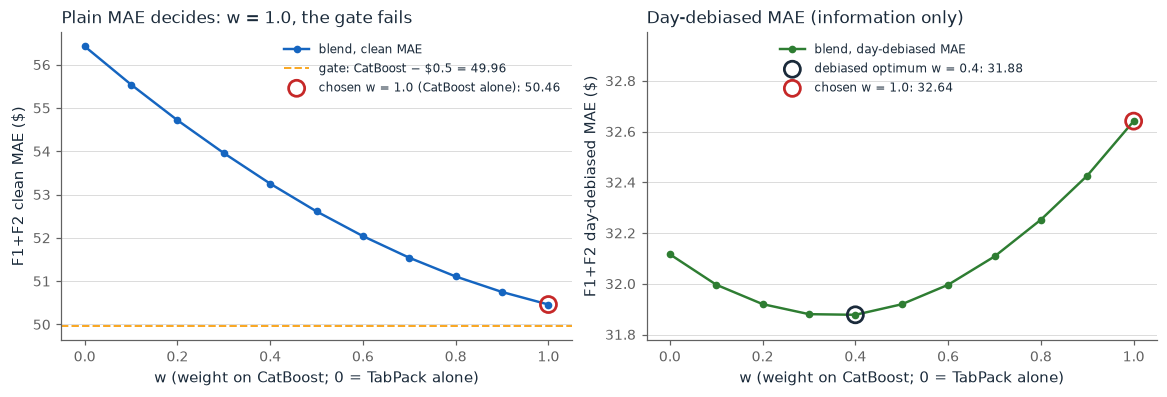

rule: w chosen by mean clean MAE over F1+F2 (grid 0..1 step 0.1); F3 scored once at the chosen w
chosen w = 1.0: gain over CatBoost on F1+F2 $0.00 → gate (> $0.5) fails; F3 at the chosen w $37.30 (CatBoost's 3-seed log-mean), TabPack alone $39.80
information only, at the debiased optimum w = 0.4: debiased MAE vs CatBoost F1+F2 -0.76 [-0.98, -0.56], F3 -0.76 [-0.99, -0.51] (day-block bootstrap 95% CI)
not pre-specified, never selectable: CatBoost + tp_standalone at w = 0.6 scores $42.52 on F1+F2 ($7.9 better than CatBoost) but $43.20 on F3 against $37.30: two opposite F2 level errors cancelling
final fit, for information: TabPack's own Nov–Dec predictions sit 0.42% above CatBoost's (median ratio; correlation 0.99992); its December curve $835.02–$888.76 (mean $857.28) vs the submitted $831.84–$883.92 (mean $852.88)


**Takeaway: a stronger learner is not the bottleneck. TabPack's cross-section is slightly better (day-debiased MAE −$0.76 on F3 at the best blend), but its level offset costs more on plain MAE, so the rule keeps CatBoost alone (w = 1.0, gate fails) and the submission is unchanged. The better learner was worth about $1; the decomposition was worth about $20 on F3 (cb_time → L + CatBoost).**

In [32]:
# Figure 14: the blend w · log p_CB + (1 − w) · log p_TP on F1+F2 (CatBoost = cb_level_noqs, TabPack = tp_level,
# seed means of the log predictions; tabpack/blend.json).
bl = read_json("tabpack/blend.json")
grid = pd.DataFrame(bl["f12_grid"])
grid["w"] = grid["w"].round(1)
grid = grid.set_index("w")
w_star, w_deb = bl["chosen_w"], bl["chosen_w_by_debiased_info"]
cb_f12 = bl["f12"]["catboost"]

fig, (axc, axd) = plt.subplots(1, 2, figsize=(10.5, 3.5), layout="constrained")
axc.plot(grid.index, grid["mae_clean"], color=BLUE, marker="o", ms=4, lw=1.6, label="blend, clean MAE")
axc.axhline(cb_f12 - 0.5, color=AMBER, ls="--", lw=1.3, label=f"gate: CatBoost − $0.5 = {cb_f12 - 0.5:.2f}")
axc.scatter([w_star], [grid.loc[w_star, "mae_clean"]], s=110, facecolor="none", edgecolor=RED, lw=1.8, zorder=4,
            label=f"chosen w = {w_star:.1f} (CatBoost alone): {grid.loc[w_star, 'mae_clean']:.2f}")
axc.set_xlabel("w (weight on CatBoost; 0 = TabPack alone)")
axc.set_ylabel("F1+F2 clean MAE ($)")
axc.set_title("Plain MAE decides: w = 1.0, the gate fails", loc="left")
axc.legend(fontsize=8, loc="upper right")
axd.plot(grid.index, grid["mae_debiased"], color=GREEN, marker="o", ms=4, lw=1.6, label="blend, day-debiased MAE")
axd.scatter([w_deb], [grid.loc[w_deb, "mae_debiased"]], s=110, facecolor="none", edgecolor=INK, lw=1.8, zorder=4,
            label=f"debiased optimum w = {w_deb:.1f}: {grid.loc[w_deb, 'mae_debiased']:.2f}")
axd.scatter([w_star], [grid.loc[w_star, "mae_debiased"]], s=110, facecolor="none", edgecolor=RED, lw=1.8, zorder=4,
            label=f"chosen w = {w_star:.1f}: {grid.loc[w_star, 'mae_debiased']:.2f}")
axd.set_xlabel("w (weight on CatBoost; 0 = TabPack alone)")
axd.set_ylabel("F1+F2 day-debiased MAE ($)")
axd.set_title("Day-debiased MAE (information only)", loc="left")
axd.legend(fontsize=8, loc="upper center")
axd.set_ylim(grid["mae_debiased"].min() - 0.1, grid["mae_debiased"].max() + 0.35)
plt.show()

gate, boot, f3 = bl["final_fit_gate"], bl["bootstrap_debiased_blend_minus_cb_info"], bl["per_fold_at_w"]["F3"]
print(f"rule: {bl['protocol']}")
print(f"chosen w = {w_star:.1f}: gain over CatBoost on F1+F2 ${gate['gain']:.2f} → gate (> $0.5) "
      f"{'passes' if gate['passes'] else 'fails'}; F3 at the chosen w ${f3['blend']['mae_clean']:.2f} (CatBoost's 3-seed "
      f"log-mean), TabPack alone ${f3['tabpack']['mae_clean']:.2f}")
print(f"information only, at the debiased optimum w = {boot['w']}: debiased MAE vs CatBoost "
      + ", ".join(f"{k} {boot[k]['delta']:+.2f} [{boot[k]['ci95_low']:+.2f}, {boot[k]['ci95_high']:+.2f}]" for k in ["F1+F2", "F3"])
      + " (day-block bootstrap 95% CI)")
sa = pd.DataFrame(bl["tp_standalone_f12_grid_info"])
sa["w"] = sa["w"].round(1)
sa = sa.set_index("w")
bg = read_csv("tabpack/blend_grid.csv")
sa_f3 = bg[(bg["blend"] == "cb+tp_standalone") & (bg["fold"] == "F3") & (bg["w"].round(1) == 0.6)]["mae_clean"].iloc[0]
print(f"not pre-specified, never selectable: CatBoost + tp_standalone at w = 0.6 scores ${sa.loc[0.6, 'mae_clean']:.2f} on "
      f"F1+F2 (${cb_f12 - sa.loc[0.6, 'mae_clean']:.1f} better than CatBoost) but ${sa_f3:.2f} on F3 against "
      f"${f3['catboost']['mae_clean']:.2f}: two opposite F2 level errors cancelling")
fs = read_json("tabpack/final/final_summary.json")
dc = fs["december_chart"]
print(f"final fit, for information: TabPack's own Nov–Dec predictions sit "
      f"{fs['validation']['median_ratio_tabpack_over_catboost'] - 1:.2%} above CatBoost's (median ratio; correlation "
      f"{fs['validation']['corr_tabpack_vs_catboost']:.5f}); its December curve ${dc['tabpack']['min']:.2f}–"
      f"${dc['tabpack']['max']:.2f} (mean ${dc['tabpack']['mean']:.2f}) vs the submitted ${dc['catboost']['min']:.2f}–"
      f"${dc['catboost']['max']:.2f} (mean ${dc['catboost']['mean']:.2f})")
decomp_gain = tpa.loc[("cb_time", "F3"), "mae_clean"] - cb.loc["F3", "mae_clean"]
takeaway(f"a stronger learner is not the bottleneck. TabPack's cross-section is slightly better (day-debiased "
         f"MAE −${-boot['F3']['delta']:.2f} on F3 at the best blend), but its level offset costs more on plain MAE, so the "
         f"rule keeps CatBoost alone (w = {w_star:.1f}, gate fails) and the submission is unchanged. The better learner "
         f"was worth about $1; the decomposition was worth about ${decomp_gain:.0f} on F3 (cb_time → L + CatBoost).")

## 12. Limitations and next steps

**Question.** What could make the Nov–Dec numbers wrong, and how large is each risk?

- **Holidays are not modelled.** Thanksgiving (Nov 27) and Christmas (Dec 25) have no Jan–Oct analogue: the
  labelled history contains no holiday of comparable scale to learn an effect from.
- **Trend extrapolation.** The trend is extrapolated two months past the data. Its risk is bounded by
  freezing $t$ at Oct 31 (below).
- **β_mi vs β_t.** Over short windows the two slopes trade off. The per-fold fits in Section 6 swing in
  opposite directions, and the all-data fit is the most stable estimate.
- **Flatbed.** It is the weakest segment, with the largest MAPE and bias on F3.
- **The metric is unknown.** MAE, MAPE and bias are reported. If the validation labels carry the same
  corruption as training, any metric on all rows is inflated by errors no model can avoid.

In [33]:
dec = pd.to_datetime(["2025-12-15", "2025-12-31"])
t_frozen = t_days(pd.to_datetime([train["date"].max()]))[0]
freeze = {f"{x:%b %d}": np.expm1(-b["t"] * (t_days([x])[0] - t_frozen)) for x in dec}
folds_c = pd.DataFrame(coefs["folds"]).T.drop(index="ALL")[["mi_day_mean", "t"]].astype(float)
f3_row = fc.loc[("cb_level_tuned", "F3")]
f3_flag = ot["F3_test"]["flagged"] / ot["F3_test"]["n"]
flat = eq_view.set_index("equipment").loc["Flatbed"]
risks = pd.DataFrame([
    {"risk": "trend extrapolation", "measured size": f"freezing t at {train['date'].max():%b %d} lowers the chart by "
     + " / ".join(f"{pct(v)} on {k}" for k, v in freeze.items())},
    {"risk": "β_mi vs β_t trade-off", "measured size": f"per-fold β_mi {folds_c['mi_day_mean'].min():.3f}–{folds_c['mi_day_mean'].max():.3f}, "
     f"β_t {100 * 30 * folds_c['t'].min():.2f}–{100 * 30 * folds_c['t'].max():.2f}% / 30 days; the fold with the lowest β_mi "
     f"({folds_c['mi_day_mean'].idxmin()}) has the highest β_t ({folds_c['t'].idxmax()})"},
    {"risk": "level extrapolation (all folds)", "measured size": "second-month bias of the final design: "
     + ", ".join(f"{f} {pct(fc.loc[('cb_level_tuned', f), 'bias_m2_mean'])}" for f in ["F1", "F2", "F3"])},
    {"risk": "Flatbed segment", "measured size": f"F3 MAPE {flat['final MAPE %']:.2f}%, median bias {flat['final median bias %']:+.2f}%"},
    {"risk": "unknown metric / corrupted labels", "measured size": f"{f3_flag:.1%} of F3 test rows are corrupted; F3 MAE all "
     f"${f3_row['mae_all_mean']:.1f} vs clean ${f3_row['mae_clean_mean']:.1f}"},
    {"risk": "weekly wave slightly amplified", "measured size": "L's single market_index slope overstates the within-week swing "
     "(sanity.md §2: " + re.search(r"about (±[\d.]+%)", md_section(sanity_path, 2)).group(1) + " at the peak and trough)"},
])
show(risks)
takeaway(f"the main risks are the unmodelled holidays and the trend extrapolation. Freezing the trend would move "
         f"mid-to-late December by only {pct(list(freeze.values())[0], 1)} to {pct(list(freeze.values())[1], 1)}, which "
         f"is below the model's ~{f3_row['mape_clean_mean']:.1f}% error.")

risk,measured size
trend extrapolation,freezing t at Oct 31 lowers the chart by -0.75% on Dec 15 / -1.02% on Dec 31
β_mi vs β_t trade-off,"per-fold β_mi 0.088–0.124, β_t 0.42–0.76% / 30 days; the fold with the lowest β_mi (F2) has the highest β_t (F2)"
level extrapolation (all folds),"second-month bias of the final design: F1 -2.14%, F2 +2.55%, F3 -1.12%"
Flatbed segment,"F3 MAPE 1.97%, median bias -1.46%"
unknown metric / corrupted labels,1.5% of F3 test rows are corrupted; F3 MAE all $93.5 vs clean $37.5
weekly wave slightly amplified,L's single market_index slope overstates the within-week swing (sanity.md §2: ±0.16% at the peak and trough)


**Takeaway: the main risks are the unmodelled holidays and the trend extrapolation. Freezing the trend would move mid-to-late December by only -0.8% to -1.0%, which is below the model's ~1.6% error.**

**Next steps.**
1. **Holiday priors.** Add holiday-window terms to L (Thanksgiving week, Christmas to New Year). Estimate them
   from prior-year data, or from industry spot-rate seasonality if no history is available.
2. **TabPack without its handicaps.** Section 11 found a slightly better cross-section but a worse level offset.
   Refit TabPack on train + inner validation with a fixed epoch count, which removes the four-week holdout behind
   the likely offset, or use it only inside the blend on a level-corrected target, so that only its
   cross-sectional gain enters.
3. **Level model.** Add per-equipment level slopes, since Flatbed is the weakest segment. Refit L on a rolling
   window as new labels arrive. Monitor the realised daily index against L to catch trend breaks early.
4. **Metric alignment.** Once Spotter's metric is known, align the loss (e.g. a quantile or MAPE-style
   objective) and the corrupted-label policy with it.